## SwiGLU 8 results: does local fitting still matter after recovery?

SwiGLU-7 builds each compressed model in two steps. A **local fit** trains every narrowed MLP to imitate its dense original on cached activations; **recovery** then distils the whole model from the dense teacher. SwiGLU-8 asks three things: whether the first step is still worth doing after the second, whether the first step itself can be done better, and what the homogeneous SwiGLU baseline looks like across 20-80% compression.

**Answers in brief**

| Question | Answer | Section |
| --- | --- | --- |
| Can the local fit be improved? | No. 14 alternatives (246 fits, 3 seeds) all miss the 5% adoption bar. The closest gains 4.4% at 8K tokens but loses 6% at 128 tokens, so Part B keeps SwiGLU-7's recipe. | 2 |
| Does local fitting still matter after 100M recovery tokens? | Yes, at this budget. Without it, 8K KL is 10.4-23.5% higher at every target. The fitted models reach the slice-only models' 100M quality after about 13-49M tokens. | 3 |
| Will it still matter at 1B tokens? | Open. The gap was still shrinking between 50M and 100M, so the decided rule rates every target *inconclusive at 100M*. A power-law extrapolation gives about 4-8% at 1B; that is a curve fit, not a measurement. | 3, 6 |
| Is the gap larger than noise? | Yes. Repeating a run changes monitoring KL by at most 0.4% at 10M tokens and by up to 3.5% at a single checkpoint; the gap is 8-24%. | 3 |
| What does context length change? | Fitting on 8K-token windows helps the 8K score mainly in layer 3 (about +10%), barely in layer 11, not in layer 19, and costs the 128-token score everywhere. After recovery, MLP removal costs relatively more at short context, and the fitted advantage is about the same at 128 and 8K tokens. | 4 |
| What is the homogeneous control spectrum? | From 20% to 80% eligible-MLP removal (13-52% of all parameters), 8K KL rises from 0.079 to 0.543, 8K test perplexity from 7.73 to 14.97 (dense 6.93), and macro accuracy falls from 62.8% to 47.0% (dense 67.1%). | 5 |

The notebook reads completed artifacts only; it loads no model and runs no training. The experiment report is `docs/experiments/model/swiglu/swiglu-8.md`.

#### Setup

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from matplotlib.ticker import FixedLocator, FuncFormatter, LogLocator, NullFormatter, NullLocator

# Seaborn's default theme; constrained layout keeps panel titles, legends and notes from overlapping.
sns.set_theme(rc={'figure.dpi': 120, 'figure.constrained_layout.use': True})

In [2]:
PROJECT_ROOT = next(
    path for path in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
    if (path / 'src' / 'mlp_replacement').is_dir()
)
S8_RESULTS = PROJECT_ROOT / 'data/results/workflows/model/swiglu-8'
S7_RESULTS = PROJECT_ROOT / 'data/results/workflows/model/swiglu-7'
BLOCK_CHECK_PATH = S8_RESULTS / 'block-check-001/result.json'
PREPARED_PATH = S8_RESULTS / 'prepare-001/result.json'
ARMS = ('fitted', 'slice')
TARGETS = (0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.75, 0.8)
REPRODUCTION_TARGETS = (0.2, 0.3, 0.4, 0.5)
RUN_PATHS = {
    (arm, target): S8_RESULTS / f'{arm}-target-{target}-run-001/result.json'
    for arm in ARMS for target in TARGETS
}
# First attempts of the fitted 20-50% runs, stopped by the original B2 check; they measure run-to-run noise.
FIRST_ATTEMPT_PATHS = {
    target: S8_RESULTS / f'fitted-target-{target}-run-001-b2-stopped/result.json' for target in REPRODUCTION_TARGETS
}
# SwiGLU-7 S7-0: the fitted recipe recovered to 1B tokens, used for the next-work outlook.
SWIGLU7_RUN_PATHS = {target: S7_RESULTS / f'S7-0-target-{target}-run-001/result.json' for target in REPRODUCTION_TARGETS}
# Earlier evidence for the local-fitting choices in section 2, read only.
SWIGLU3_PATH = PROJECT_ROOT / 'data/results/workflows/model/swiglu-3/run-001.json'
OPERATOR_DISTILLATION_PATH = PROJECT_ROOT / 'data/results/notebook-block-study/operator-distillation-v4.json'

ORIGINAL_WIDTH = 8192
CURRENT_SETTING = 'c1e-3-128'  # SwiGLU-7's local-fitting recipe; Part A changes are relative to it
# Decided interpretation (decision log, 2026-10-10 and 2026-10-11): each target is judged by the 8K KL gap
# at 100M; the monitoring gap is stable if it moves less than one percentage point from 50M to 100M.
# The 2% threshold is a judgment call.
GAP_THRESHOLD = 0.02
STABILITY_THRESHOLD = 0.01
REVIEW_LIMIT = 0.01  # B2 review limit for the SwiGLU-7 reproduction (decision log, 2026-10-12)
EXTRAPOLATION_TOKENS = 1_000_000_000  # only for the labelled power-law extrapolation
TASKS = {'piqa': 'PIQA', 'arc_easy': 'ARC-Easy', 'arc_challenge': 'ARC-Challenge',
         'winogrande': 'WinoGrande', 'hellaswag': 'HellaSwag'}
CHANCE_ACCURACY = {'piqa': 0.5, 'arc_easy': 0.25, 'arc_challenge': 0.25, 'winogrande': 0.5, 'hellaswag': 0.25}
# Pre-run plan (swiglu-8.md) and job requests (swiglu_8.sbatch, perun-runbook.md): 1 H200, 8 CPUs, 128 GB per job.
PLANNED_GPU_HOURS = {'block-check': (16, 31), 'prepare': (3, 8), 'train': (20, 24)}
REQUESTED_HOURS = {'block-check': 6, 'prepare': 24, 'train': 6}
REQUESTED_RAM_GB = 128

ARM_LABELS = {'fitted': 'Fitted', 'slice': 'Slice only'}
ARM_COLORS = {'fitted': '#0072B2', 'slice': '#D55E00'}
DENSE_COLOR = '#444444'
NOTE_COLOR = '#777777'
TARGET_COLORS = dict(zip(TARGETS, plt.get_cmap('viridis')(np.linspace(0.0, 0.85, len(TARGETS)))))
SHOWCASE_TARGETS = {0.2: 'Low', 0.5: 'Mid', 0.8: 'High'}  # sparsity levels shown in detail

In [3]:
def load_artifact(path, workflow, command):
    artifact = json.loads(path.read_text(encoding='utf-8'))
    if (artifact.get('workflow'), artifact.get('command')) != (workflow, command):
        raise ValueError(f'Unexpected artifact: {path}')
    return artifact


def requested_tokens(row):
    tokens = row['requested_tokens']
    return max(tokens) if isinstance(tokens, list) else tokens


def workflow_hours(artifact):
    span = pd.Timestamp(artifact['updated_at_utc']) - pd.Timestamp(artifact['created_at_utc'])
    return span.total_seconds() / 3600


def acceptance_frame(groups, stage, run='-'):
    return pd.DataFrame([
        {
            'Stage': stage, 'Run': run, 'Group': group, 'Metric': check.get('metric') or check['check'],
            'Layer': check.get('layer'), 'Width': check.get('width'), 'Tokens': check.get('tokens'),
            'Value': check['value'], 'Reference': check.get('reference'),
            'Relative difference': check.get('relative_difference'), 'Tolerance': check.get('tolerance'),
            'Passed': bool(check['passed']),
        }
        for group, summary in groups.items() for check in summary['checks']
    ])


def show_table(frame, caption, formats=None):
    display(
        frame.style.hide(axis='index').format(formats or {}, na_rep='-').set_caption(caption)
        .set_table_styles([
            {'selector': 'caption',
             'props': 'caption-side: top; text-align: left; font-weight: bold; padding: 4px 0 8px;'},
            {'selector': 'th', 'props': 'text-align: left;'},
        ])
    )


block_check = load_artifact(BLOCK_CHECK_PATH, 'swiglu-8', 'block-check')
prepared = load_artifact(PREPARED_PATH, 'swiglu-8', 'prepare')
runs = {key: load_artifact(path, 'swiglu-8', 'train') for key, path in RUN_PATHS.items()}
for (arm, target), run in runs.items():
    if run['identity'] != {'arm': arm, 'target': target}:
        raise ValueError(f'Artifact identity mismatch: {RUN_PATHS[(arm, target)]}')
first_attempts = {target: load_artifact(path, 'swiglu-8', 'train') for target, path in FIRST_ATTEMPT_PATHS.items()}
swiglu7_runs = {target: load_artifact(path, 'swiglu-7', 'train') for target, path in SWIGLU7_RUN_PATHS.items()}

block_results = block_check['results']
prepared_results = prepared['results']
setting_grid = block_check['configuration']['block_check']['settings']
adoption = block_results['adoption']
dense = prepared_results['dense_evaluation']

acceptance_df = pd.concat([
    acceptance_frame(block_results['acceptance'], 'Part A block check'),
    acceptance_frame(prepared_results['acceptance'], 'Part B preparation'),
    *(acceptance_frame(runs[('fitted', target)]['results']['acceptance'], 'Part B recovery', f'fitted {target:.0%}')
      for target in REPRODUCTION_TARGETS),
], ignore_index=True)


def acceptance_text(stage):
    rows = acceptance_df[acceptance_df['Stage'] == stage]
    return ' · '.join(
        f"{group} {int(group_rows['Passed'].sum())}/{len(group_rows)}"
        for group, group_rows in rows.groupby('Group', sort=False)
    )


run_status = pd.Series([run['status'] for run in runs.values()]).value_counts()
show_table(pd.DataFrame([
    {'Stage': 'Part A block check', 'Artifacts': f"merge + {len(block_results['tasks'])} tasks",
     'Status': block_check['status'],
     'Contents': f"{len(block_results['fits'])} fits, {len(block_results['slices'])} unfitted slices",
     'Checks within tolerance': acceptance_text('Part A block check')},
    {'Stage': 'Part B preparation', 'Artifacts': '1', 'Status': prepared['status'],
     'Contents': f"{len(prepared_results['starts'])} start models, {len(prepared_results['local_fitting'])} local fits",
     'Checks within tolerance': acceptance_text('Part B preparation')},
    {'Stage': 'Part B recovery', 'Artifacts': f'{len(runs)} runs',
     'Status': ', '.join(f'{count} {status}' for status, count in run_status.items()),
     'Contents': f'{len(TARGETS)} targets × {len(ARMS)} arms, 100M tokens each',
     'Checks within tolerance': acceptance_text('Part B recovery')},
]), 'Loaded artifacts. B2 is a 1% review limit, not a stop; its two flags are examined in section 3d')

Stage,Artifacts,Status,Contents,Checks within tolerance
Part A block check,merge + 15 tasks,completed,"246 fits, 6 unfitted slices",P5 1/1 · A1 6/6 · A2-A3 18/18
Part B preparation,1,completed,"16 start models, 121 local fits",P4 1/1 · P3 12/12 · P5 2/2 · P1 135/135 · P2 92/92
Part B recovery,16 runs,16 completed,"8 targets × 2 arms, 100M tokens each",B1 8/8 · B2 34/36


#### 1. Experiment design

Both parts use pinned SmolLM2-1.7B. The MLPs of the 22 eligible layers (1-22) are replaced; layers 0 and 23 stay dense.

| | Part A: block check | Part B: model runs |
| --- | --- | --- |
| Question | Can the local fit itself be improved? | Does the local fit still matter after recovery? |
| Unit | One MLP replaced at a time: layers 3, 11 and 19 at widths 0.25 and 0.5 | The whole compressed model at 20, 30, 40, 50, 60, 70, 75 and 80% eligible-MLP removal |
| Compared | SwiGLU-7's recipe against 14 alternatives: training context × schedule × learning rate, least squares, and batch 256, with 3 seeds each | The **fitted** arm (teacher slice, then local fit) against the **slice-only** arm (the same teacher slice, no fit) |
| Held fixed | Kept neurons, data and starting weights; seeds change only the batch order | Neurons, widths, seed 21, the ordered 100M-token recovery stream, and the S7-0 recipe (replacement MLPs only, teacher KL, constant learning rate 3e-5, 8,192-token sequences) |
| Scored by | Single-block KL, the teacher KL when only that block is replaced, at 128 and 8K tokens | KL against the teacher on 8K sequences at 100M (deciding); monitoring KL on 128-token windows from 0 to 100M; WikiText-2 perplexity; five zero-shot tasks |
| Decision rule | Adopt a setting only if its mean 8K reduction is above 5% and above the seed noise, with no combination more than 5% worse | g = (slice - fitted) / fitted. Within ±2%: fitting does not matter. Above 2% with a stable gap (change below 1 pp from 50M to 100M): fitting matters. Otherwise: inconclusive at 100M |

Every choice is made on data that the final evaluation never uses (decision log, 2026-10-11):

| Data | Used for | In the final evaluation? |
| --- | --- | --- |
| 128-token calibration pairs (393,216) | Training pairs at 128 tokens | No |
| 128-token operator validation (6,144 pairs) | Early stopping at 128 tokens | No |
| 128-token allocation selection (3,072 tokens) | Single-block KL at 128 tokens; width allocation | No |
| 8K calibration stream (48 × 8,192 tokens) | Training pairs at 8K | No |
| 8K validation stream (1 × 8,192 tokens) | Early stopping at 8K | No |
| 8K selection stream (24 × 8,192 tokens) | Single-block KL at 8K, the deciding Part A score | No |
| 128-token monitoring windows (48 × 128 tokens) | Monitoring KL during recovery | Monitoring only |
| 8K KL stream (24 × 8,192 tokens, shared with Quantization-1) | Final 8K KL at 100M | Yes |

#### 2. Learning configuration: can the local fit be improved?

Part A fits one replacement MLP at a time and scores the fit by single-block KL, so a setting is judged by its effect on the model's output, not by activation error alone. The 8K score decides; the 128-token score guards against a setting that helps long context by hurting short context. Every change below is a seed mean relative to SwiGLU-7's recipe `c1e-3-128`: constant learning rate 1e-3, 128-token training windows, batch 2,048.

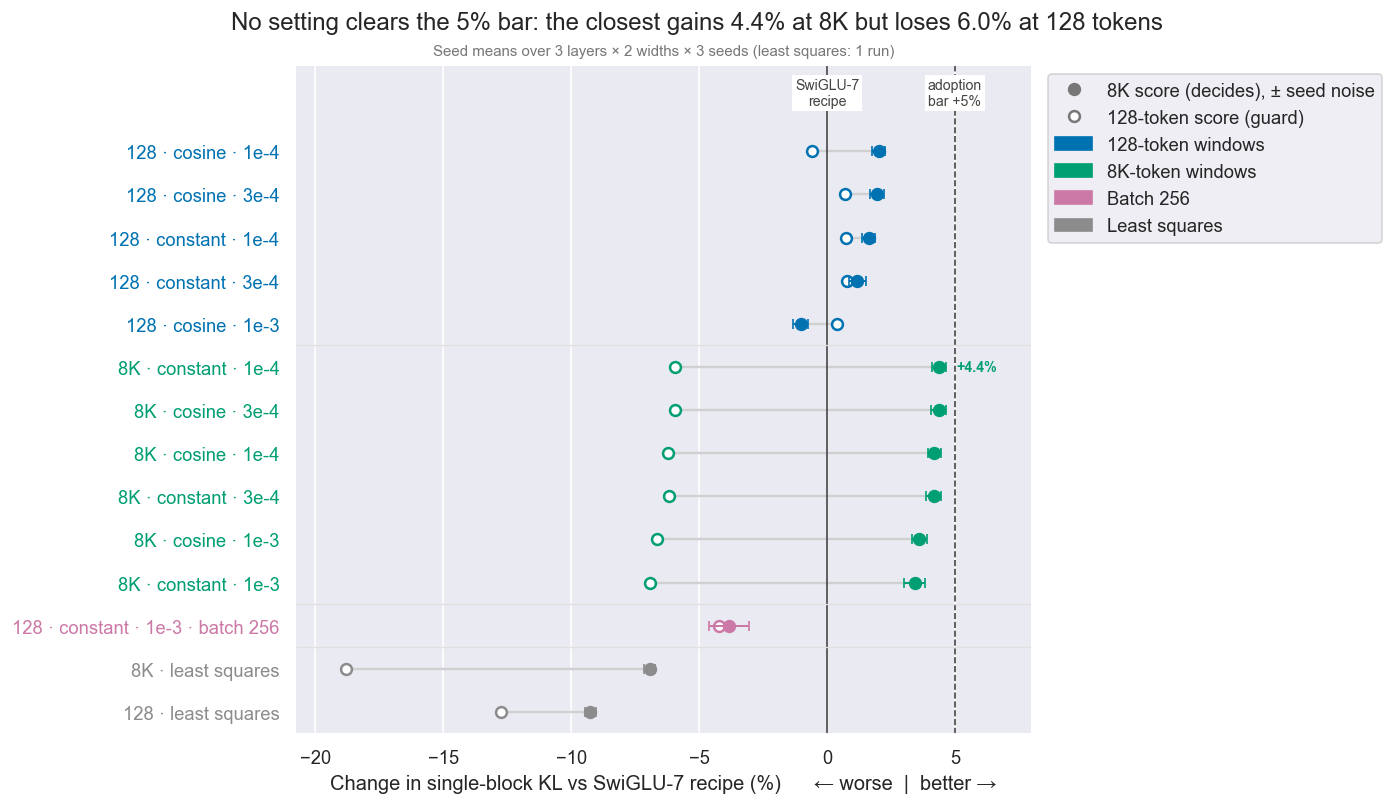

In [4]:
def rate_label(rate):
    return f'{rate:.0e}'.replace('e-0', 'e-')


def describe(name):
    setting = setting_grid[name]
    context = '8K' if setting['calibration_context'] == 8192 else '128'
    if setting['method'] == 'least_squares':
        return f'{context} · least squares'
    label = f"{context} · {setting['scheduler']} · {rate_label(setting['learning_rate'])}"
    if setting['batch_size'] != setting_grid[CURRENT_SETTING]['batch_size']:
        label += f" · batch {setting['batch_size']}"
    return label


def family(name):
    setting = setting_grid[name]
    if setting['method'] == 'least_squares':
        return 'Least squares'
    if setting['batch_size'] != setting_grid[CURRENT_SETTING]['batch_size']:
        return 'Batch 256'
    return '8K-token windows' if setting['calibration_context'] == 8192 else '128-token windows'


FAMILY_COLORS = {'128-token windows': '#0072B2', '8K-token windows': '#009E73', 'Batch 256': '#CC79A7',
                 'Least squares': '#8c8c8c'}
adoption_df = pd.DataFrame([
    {
        'Setting': name, 'Label': describe(name), 'Family': family(name),
        'Change @ 8K': row['mean_reduction']['8192'], 'Change @ 128': row['mean_reduction']['128'],
        'Seed noise': row['mean_seed_noise'], 'Worst combination': row['worst_reduction'],
        'Qualifies': row['qualifies'], 'Reasons': '; '.join(row['reasons']) or '-',
    }
    for name, row in adoption['settings'].items()
])
adoption_df['Family'] = pd.Categorical(adoption_df['Family'], list(FAMILY_COLORS), ordered=True)
adoption_df = adoption_df.sort_values(['Family', 'Change @ 8K'], ascending=[True, False], ignore_index=True)
best = adoption_df.loc[adoption_df['Change @ 8K'].idxmax()]
adoption_bar = 100 * adoption['rule']['minimum_mean_reduction']

figure, axis = plt.subplots(figsize=(11.5, 6.6))
for position, row in adoption_df.iterrows():
    color = FAMILY_COLORS[row['Family']]
    axis.plot([100 * row['Change @ 128'], 100 * row['Change @ 8K']], [position, position],
              color='#d0d0d0', linewidth=1.4, zorder=1)
    axis.errorbar(100 * row['Change @ 8K'], position, xerr=100 * row['Seed noise'], fmt='o', color=color,
                  markersize=7, capsize=3, elinewidth=1.2, zorder=3)
    axis.plot(100 * row['Change @ 128'], position, marker='o', markersize=6.5, markerfacecolor='white',
              markeredgecolor=color, markeredgewidth=1.5, linestyle='none', zorder=2)
low = 100 * adoption_df[['Change @ 8K', 'Change @ 128']].min().min() - 2
high = adoption_bar + 3
axis.axvline(0, color=DENSE_COLOR, linewidth=1)
axis.axvline(adoption_bar, color=DENSE_COLOR, linewidth=1, linestyle='--')
for position, text in ((0, 'SwiGLU-7\nrecipe'), (adoption_bar, f'adoption\nbar +{adoption_bar:.0f}%')):
    axis.text(position, -1.0, text, ha='center', va='bottom', fontsize=8.5, color=DENSE_COLOR,
              bbox={'facecolor': 'white', 'edgecolor': 'none', 'pad': 1.5})
best_position = adoption_df.index[adoption_df['Setting'] == best['Setting']][0]
axis.annotate(f"{100 * best['Change @ 8K']:+.1f}%", (100 * best['Change @ 8K'], best_position),
              xytext=(10, 0), textcoords='offset points', va='center', fontsize=8.5, fontweight='bold',
              color=FAMILY_COLORS[best['Family']])
for boundary in np.flatnonzero(adoption_df['Family'].ne(adoption_df['Family'].shift()).to_numpy())[1:]:
    axis.axhline(boundary - 0.5, color='#e0e0e0', linewidth=0.8)
axis.set_yticks(range(len(adoption_df)), adoption_df['Label'])
for tick, row_family in zip(axis.get_yticklabels(), adoption_df['Family']):
    tick.set_color(FAMILY_COLORS[row_family])
axis.set(xlim=(low, high), ylim=(len(adoption_df) - 0.5, -2.0),
         xlabel='Change in single-block KL vs SwiGLU-7 recipe (%)      ← worse  |  better →')
axis.grid(False)
axis.xaxis.grid(True)
axis.legend(handles=[
    Line2D([], [], marker='o', color=NOTE_COLOR, markersize=7, linestyle='none',
           label='8K score (decides), ± seed noise'),
    Line2D([], [], marker='o', markerfacecolor='white', markeredgecolor=NOTE_COLOR, markeredgewidth=1.5,
           markersize=6.5, linestyle='none', label='128-token score (guard)'),
    *(Patch(color=color, label=name) for name, color in FAMILY_COLORS.items()),
], loc='upper left', bbox_to_anchor=(1.01, 1.0))
axis.set_title('Seed means over 3 layers × 2 widths × 3 seeds (least squares: 1 run)', fontweight='normal',
               fontsize=9, color=NOTE_COLOR)
figure.suptitle(
    f"No setting clears the 5% bar: the closest gains {100 * best['Change @ 8K']:.1f}% at 8K "
    f"but loses {-100 * best['Change @ 128']:.1f}% at 128 tokens",
)
plt.show()

In [5]:
show_table(
    adoption_df.sort_values('Change @ 8K', ascending=False)[
        ['Setting', 'Family', 'Change @ 8K', 'Change @ 128', 'Seed noise', 'Worst combination', 'Qualifies', 'Reasons']
    ],
    'Adoption rule (decision log, 2026-10-11): mean 8K change above +5% and above the seed noise; '
    'no combination more than 5% worse at 128 or 8K',
    {'Change @ 8K': '{:+.2%}', 'Change @ 128': '{:+.2%}', 'Seed noise': '{:.2%}', 'Worst combination': '{:+.2%}'},
)
print(f"Selected for Part B: {adoption['selected_recipe']} "
      f"(qualifying settings: {', '.join(adoption['qualifying']) or 'none'})")

Setting,Family,Change @ 8K,Change @ 128,Seed noise,Worst combination,Qualifies,Reasons
c1e-4-8k,8K-token windows,+4.39%,-5.95%,0.27%,-8.51%,False,mean 8192-token reduction is not above 5%; a combination is more than 5% worse
cos3e-4-8k,8K-token windows,+4.36%,-5.94%,0.29%,-8.26%,False,mean 8192-token reduction is not above 5%; a combination is more than 5% worse
cos1e-4-8k,8K-token windows,+4.20%,-6.22%,0.26%,-10.50%,False,mean 8192-token reduction is not above 5%; a combination is more than 5% worse
c3e-4-8k,8K-token windows,+4.17%,-6.18%,0.28%,-8.32%,False,mean 8192-token reduction is not above 5%; a combination is more than 5% worse
cos1e-3-8k,8K-token windows,+3.61%,-6.66%,0.30%,-9.85%,False,mean 8192-token reduction is not above 5%; a combination is more than 5% worse
c1e-3-8k,8K-token windows,+3.43%,-6.93%,0.42%,-9.33%,False,mean 8192-token reduction is not above 5%; a combination is more than 5% worse
cos1e-4-128,128-token windows,+2.01%,-0.57%,0.25%,-7.13%,False,mean 8192-token reduction is not above 5%; a combination is more than 5% worse
cos3e-4-128,128-token windows,+1.96%,+0.70%,0.26%,-1.65%,False,mean 8192-token reduction is not above 5%
c1e-4-128,128-token windows,+1.62%,+0.76%,0.25%,-0.77%,False,mean 8192-token reduction is not above 5%
c3e-4-128,128-token windows,+1.18%,+0.77%,0.32%,+0.39%,False,mean 8192-token reduction is not above 5%


Selected for Part B: c1e-3-128 (qualifying settings: none)


##### Why the optimizer settings barely matter

Lower learning rates and cosine decay change how fast a fit converges much more than where it ends: the floors differ by about 1-2% in held-out error. At width 0.5 the SwiGLU-7 recipe reaches its best held-out error within about three epochs; after that, training error keeps falling while held-out error stops improving. This is the mild overfitting that triggered the stage-2 indicator. It suggests that the fit is limited by the 393,216 calibration pairs rather than by the optimizer. That is a hypothesis: stage 2 (more pairs, a keep-near-teacher penalty) would test it and is deferred.

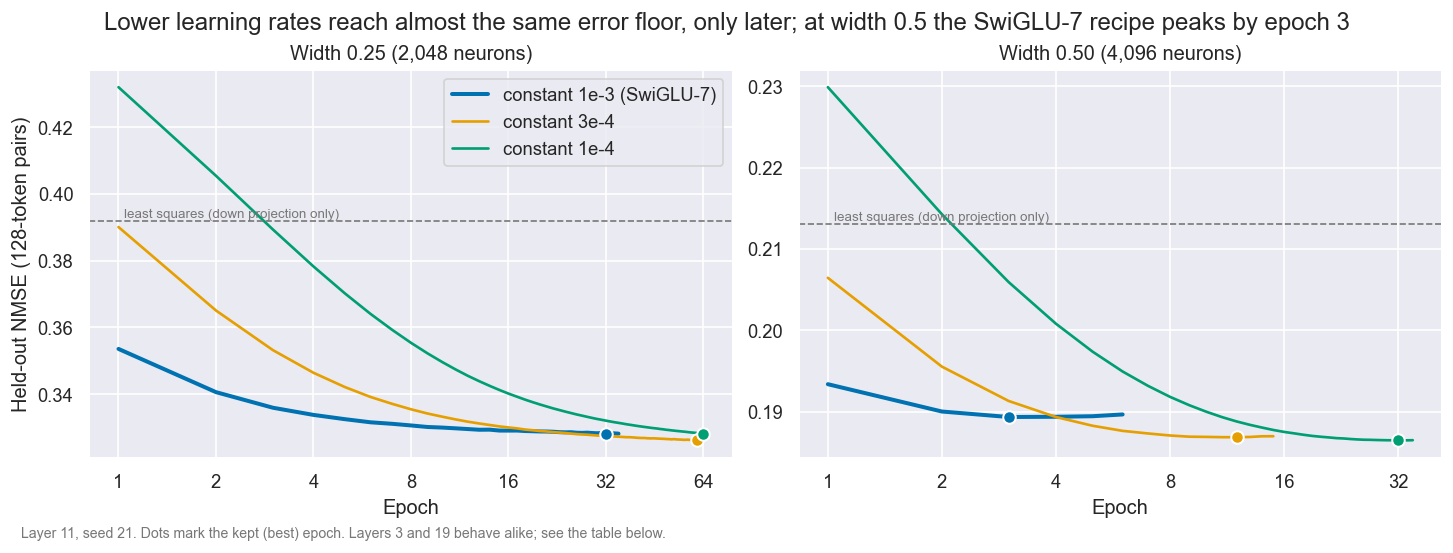

Setting,Best epoch @ 0.25,Best epoch @ 0.50,Mean fit seconds
c1e-3-128,23.9,3.1,67
c3e-4-128,47.0,9.8,127
c1e-4-128,64.0,28.1,199
cos1e-3-128,31.4,12.7,128
cos3e-4-128,32.0,13.8,132
cos1e-4-128,32.0,32.0,126
c1e-3-8k,8.6,2.3,34
c3e-4-8k,23.8,6.8,73
c1e-4-8k,49.4,20.1,148
cos1e-3-8k,22.0,2.3,137


Stage-2 indicator (best epoch <= 3 while training MSE still falls, at width 0.5, in most seeds of a layer): overfitting in layers [3, 11, 19]. Stage 2 is deferred (decision log, 2026-10-11).


In [6]:
fits_df = pd.DataFrame([
    {
        'Setting': row['setting'], 'Seed': row['seed'], 'Layer': row['layer'], 'Width ratio': row['width_ratio'],
        'KL @ 128': row['kl_128'], 'KL @ 8K': row['kl_8192'], 'NMSE @ 128': row['validation_128']['nmse'],
        'Best epoch': row.get('best_epoch'), 'Epochs': row.get('epochs_completed'),
        'Fit seconds': row.get('fit_seconds'),
    }
    for row in [*block_results['slices'], *block_results['fits']]
])
stage_two = block_results['stage_two_indicator']
DYNAMICS_LAYER = 11
DYNAMICS_SETTINGS = {
    'c1e-3-128': ('constant 1e-3 (SwiGLU-7)', '#0072B2'),
    'c3e-4-128': ('constant 3e-4', '#E69F00'),
    'c1e-4-128': ('constant 1e-4', '#009E73'),
}
WIDTH_RATIOS = sorted(fits_df['Width ratio'].unique())

figure, axes = plt.subplots(1, 2, figsize=(12, 4.3))
for axis, width in zip(axes, WIDTH_RATIOS):
    for name, (label, color) in DYNAMICS_SETTINGS.items():
        fit = next(row for row in block_results['fits']
                   if (row['setting'], row['seed'], row['layer'], row['width_ratio']) == (name, 21, DYNAMICS_LAYER, width))
        epochs = [entry['epoch'] for entry in fit['history']]
        errors = [entry['validation_nmse'] for entry in fit['history']]
        axis.plot(epochs, errors, color=color, label=label, linewidth=2.4 if name == CURRENT_SETTING else 1.6)
        axis.plot(fit['best_epoch'], errors[epochs.index(fit['best_epoch'])], marker='o', markersize=7.5,
                  color=color, markeredgecolor='white', markeredgewidth=1.2, linestyle='none', zorder=4)
    least_squares = fits_df[(fits_df['Setting'] == 'ols-128') & (fits_df['Layer'] == DYNAMICS_LAYER)
                            & (fits_df['Width ratio'] == width)]['NMSE @ 128'].iloc[0]
    axis.axhline(least_squares, color=NOTE_COLOR, linestyle='--', linewidth=1)
    axis.text(1.04, least_squares, 'least squares (down projection only)', color=NOTE_COLOR, fontsize=8,
              va='bottom')
    axis.set(xscale='log', xlabel='Epoch', title=f'Width {width:.2f} ({int(width * ORIGINAL_WIDTH):,} neurons)')
    axis.xaxis.set_major_locator(FixedLocator([1, 2, 4, 8, 16, 32, 64]))
    axis.xaxis.set_major_formatter(FuncFormatter(lambda value, _: f'{value:g}'))
    axis.xaxis.set_minor_locator(NullLocator())
axes[0].set_ylabel('Held-out NMSE (128-token pairs)')
axes[0].legend(loc='upper right')
current_best = fits_df[(fits_df['Setting'] == CURRENT_SETTING) & (fits_df['Width ratio'] == WIDTH_RATIOS[-1])]['Best epoch']
figure.suptitle(
    f'Lower learning rates reach almost the same error floor, only later; at width {WIDTH_RATIOS[-1]:.1f} '
    f'the SwiGLU-7 recipe peaks by epoch {current_best.mean():.0f}',
)
figure.text(0.01, -0.03, f'Layer {DYNAMICS_LAYER}, seed 21. Dots mark the kept (best) epoch. Layers 3 and 19 '
            'behave alike; see the table below.', fontsize=8.5, color=NOTE_COLOR)
plt.show()

gradient_settings = [name for name, setting in setting_grid.items() if setting['method'] == 'gradient']
dynamics_df = (
    fits_df[fits_df['Setting'].isin(gradient_settings)]
    .groupby(['Setting', 'Width ratio'])['Best epoch'].mean().unstack('Width ratio')
    .reindex(gradient_settings)
)
dynamics_df.columns = [f'Best epoch @ {width:.2f}' for width in dynamics_df.columns]
dynamics_df['Mean fit seconds'] = fits_df.groupby('Setting')['Fit seconds'].mean().reindex(gradient_settings)
show_table(
    dynamics_df.reset_index(),
    'Mean best epoch over 3 layers × 3 seeds; cosine settings always run 32 epochs and keep their best epoch',
    {column: '{:.1f}' for column in dynamics_df.columns[:-1]} | {'Mean fit seconds': '{:.0f}'},
)
print(f"Stage-2 indicator ({stage_two['definition']}): overfitting in layers {stage_two['overfitting_layers']}. "
      'Stage 2 is deferred (decision log, 2026-10-11).')

##### Why each setting was kept

The table gives the reason for every local-fitting setting used by the replacements. Part A rows are seed means relative to `c1e-3-128`. The calibration-size and initialization rows come from earlier, narrower studies (SwiGLU-3; operator distillation, layer 11, one seed) and are labelled as such.

In [7]:
earlier = {
    name: json.loads(path.read_text(encoding='utf-8'))
    for name, path in (('swiglu-3', SWIGLU3_PATH), ('operator-distillation', OPERATOR_DISTILLATION_PATH))
    if path.is_file()
}


def change_text(name):
    row = adoption['settings'][name]
    return f"{describe(name)}: {row['mean_reduction']['8192']:+.1%} at 8K, {row['mean_reduction']['128']:+.1%} at 128"


long_context_settings = [name for name in setting_grid if family(name) == '8K-token windows']
long_context_8k = [adoption['settings'][name]['mean_reduction']['8192'] for name in long_context_settings]
long_context_128 = [adoption['settings'][name]['mean_reduction']['128'] for name in long_context_settings]
batch_best_epoch = fits_df[(fits_df['Setting'] == f'{CURRENT_SETTING}-b256')
                           & (fits_df['Width ratio'] == WIDTH_RATIOS[-1])]['Best epoch'].mean()
if 'swiglu-3' in earlier:
    calibration_rows = earlier['swiglu-3']['results']['calibration']['model_evaluation']
    calibration_kl = [row['allocation_selection']['teacher_kl'] for row in calibration_rows]
    doubling_gains = [1 - after / before for before, after in zip(calibration_kl, calibration_kl[1:])]
    calibration_evidence = ('SwiGLU-3 allocation KL ' + ' → '.join(
        f"{row['calibration_pairs']:,}: {kl:.4f}" for row, kl in zip(calibration_rows, calibration_kl)))
    calibration_reason = (f'Largest tested and lowest KL; each doubling gave {min(doubling_gains):.1%}-'
                          f'{max(doubling_gains):.1%}. 786,432 pairs belongs to stage 2, deferred')
else:
    calibration_evidence = 'SwiGLU-3 allocation KL 0.4025 → 0.3889 → 0.3739 (documented; file not available locally)'
    calibration_reason = 'Largest tested and lowest KL; 786,432 pairs belongs to stage 2, deferred'
if 'operator-distillation' in earlier:
    operator_results = earlier['operator-distillation']['results']
    initialization_evidence = '; '.join(
        f"{row['initialization'].replace('_', ' ')}: NMSE {row['fitted_nmse']:.4f}, best epoch {row['best_epoch']}"
        for row in operator_results['teacher_initialization']['summary']
    )
    batch_row = max(operator_results['combined']['comparison'], key=lambda row: row['calibration_tokens'])
    earlier_batch = (f"earlier study at {batch_row['calibration_tokens']:,} pairs: NMSE {batch_row['original_nmse']:.4f} "
                     f"(2,048) vs {batch_row['optimized_nmse']:.4f} (256)")
else:
    initialization_evidence = ('random weights: NMSE 0.4666; random teacher subset: 0.2655; importance teacher '
                               'subset: 0.2038 (documented; file not available locally)')
    earlier_batch = 'earlier study at 98,304 pairs: NMSE 0.4666 (2,048) vs 0.4668 (256) (documented)'

why_df = pd.DataFrame([
    {'Setting': 'Learning rate', 'Kept': '1e-3', 'Tested instead': '3e-4, 1e-4',
     'Evidence': '; '.join(change_text(name) for name in ('c3e-4-128', 'c1e-4-128')),
     'Why kept': 'Gains below 2%; lower rates reach the same error floor later'},
    {'Setting': 'Schedule', 'Kept': 'constant', 'Tested instead': 'cosine decay over 32 epochs',
     'Evidence': '; '.join(change_text(name) for name in ('cos1e-3-128', 'cos3e-4-128', 'cos1e-4-128')),
     'Why kept': 'At most +2% on average; two cosine settings are more than 5% worse in one combination'},
    {'Setting': 'Training context', 'Kept': '128-token windows', 'Tested instead': '8K-token windows, six settings',
     'Evidence': f'{min(long_context_8k):+.1%} to {max(long_context_8k):+.1%} at 8K; '
                 f'{min(long_context_128):+.1%} to {max(long_context_128):+.1%} at 128',
     'Why kept': 'Below the 5% bar at 8K, and every setting is more than 5% worse in some combination at 128 tokens; '
                 'the gain comes mainly from layer 3 (section 4a)'},
    {'Setting': 'Solve method', 'Kept': 'gradient training of all three projections',
     'Tested instead': 'exact least squares for the down projection',
     'Evidence': '; '.join(change_text(name) for name in ('ols-128', 'ols-8k')),
     'Why kept': 'Worse at both contexts: least squares cannot adjust the teacher-slice gate and up projections'},
    {'Setting': 'Batch size', 'Kept': '2,048', 'Tested instead': '256',
     'Evidence': f"{change_text(f'{CURRENT_SETTING}-b256')}; {earlier_batch}",
     'Why kept': f'Worse here: with 8× more updates per epoch it peaks at epoch {batch_best_epoch:.0f} at width '
                 f'{WIDTH_RATIOS[-1]:.1f}'},
    {'Setting': 'Calibration size', 'Kept': '393,216 pairs', 'Tested instead': '98,304 and 196,608 (SwiGLU-3)',
     'Evidence': calibration_evidence, 'Why kept': calibration_reason},
    {'Setting': 'Initialization', 'Kept': 'importance-ranked teacher slice',
     'Tested instead': 'random weights; random teacher subset (operator distillation)',
     'Evidence': initialization_evidence, 'Why kept': 'Lowest fitted error and fastest convergence'},
])
display(
    why_df.style.hide(axis='index').set_caption('Why each local-fitting setting was kept')
    .set_properties(**{'text-align': 'left', 'white-space': 'normal'})
    .set_table_styles([
        {'selector': 'caption', 'props': 'caption-side: top; text-align: left; font-weight: bold; padding: 4px 0 8px;'},
        {'selector': 'th', 'props': 'text-align: left;'},
    ])
)

Setting,Kept,Tested instead,Evidence,Why kept
Learning rate,1e-3,"3e-4, 1e-4","128 · constant · 3e-4: +1.2% at 8K, +0.8% at 128; 128 · constant · 1e-4: +1.6% at 8K, +0.8% at 128",Gains below 2%; lower rates reach the same error floor later
Schedule,constant,cosine decay over 32 epochs,"128 · cosine · 1e-3: -1.0% at 8K, +0.4% at 128; 128 · cosine · 3e-4: +2.0% at 8K, +0.7% at 128; 128 · cosine · 1e-4: +2.0% at 8K, -0.6% at 128",At most +2% on average; two cosine settings are more than 5% worse in one combination
Training context,128-token windows,"8K-token windows, six settings",+3.4% to +4.4% at 8K; -6.9% to -5.9% at 128,"Below the 5% bar at 8K, and every setting is more than 5% worse in some combination at 128 tokens; the gain comes mainly from layer 3 (section 4a)"
Solve method,gradient training of all three projections,exact least squares for the down projection,"128 · least squares: -9.3% at 8K, -12.7% at 128; 8K · least squares: -6.9% at 8K, -18.8% at 128",Worse at both contexts: least squares cannot adjust the teacher-slice gate and up projections
Batch size,"2,048",256,"128 · constant · 1e-3 · batch 256: -3.8% at 8K, -4.2% at 128; earlier study at 98,304 pairs: NMSE 0.4666 (2,048) vs 0.4668 (256)",Worse here: with 8× more updates per epoch it peaks at epoch 1 at width 0.5
Calibration size,"393,216 pairs","98,304 and 196,608 (SwiGLU-3)","SwiGLU-3 allocation KL 98,304: 0.4025 → 196,608: 0.3889 → 393,216: 0.3739","Largest tested and lowest KL; each doubling gave 3.4%-3.9%. 786,432 pairs belongs to stage 2, deferred"
Initialization,importance-ranked teacher slice,random weights; random teacher subset (operator distillation),"random weights: NMSE 0.4666, best epoch 26; random teacher subset: NMSE 0.2655, best epoch 7; importance teacher subset: NMSE 0.2038, best epoch 4",Lowest fitted error and fastest convergence


Limits of the Part A evidence:

- Three layers (3, 11 and 19) at two widths (25% and 50%). Other layers and the narrow widths 512 and 1,024 are not tested.
- Seeds vary only the batch order; a different calibration sample could move the results more.
- One model (SmolLM2-1.7B) and one local objective (activation MSE).
- The 128-token score uses 3,072 tokens. Every setting is scored on the same windows, so differences between settings are less noisy than the absolute values.
- The batch-size, calibration-size and initialization evidence from earlier studies is narrower and is labelled as such.

#### 3. Local fit versus no local fit

Both arms start from the same importance-ranked teacher slice at the same widths, use seed 21, and see the identical ordered 100M-token recovery stream. The only difference is the local fit, so the comparison is paired, with one run per arm and target.

##### a. The divergence during recovery

Monitoring KL is measured on 48 held-out 128-token C4 windows at 0, 10, 25, 50, 75 and 100M tokens. The gap is g(t) = slice / fitted - 1. In panel d, the dashed lines extend a power law fitted to each target's 10-100M gaps out to 1B tokens. They are an extrapolation, not a measurement.

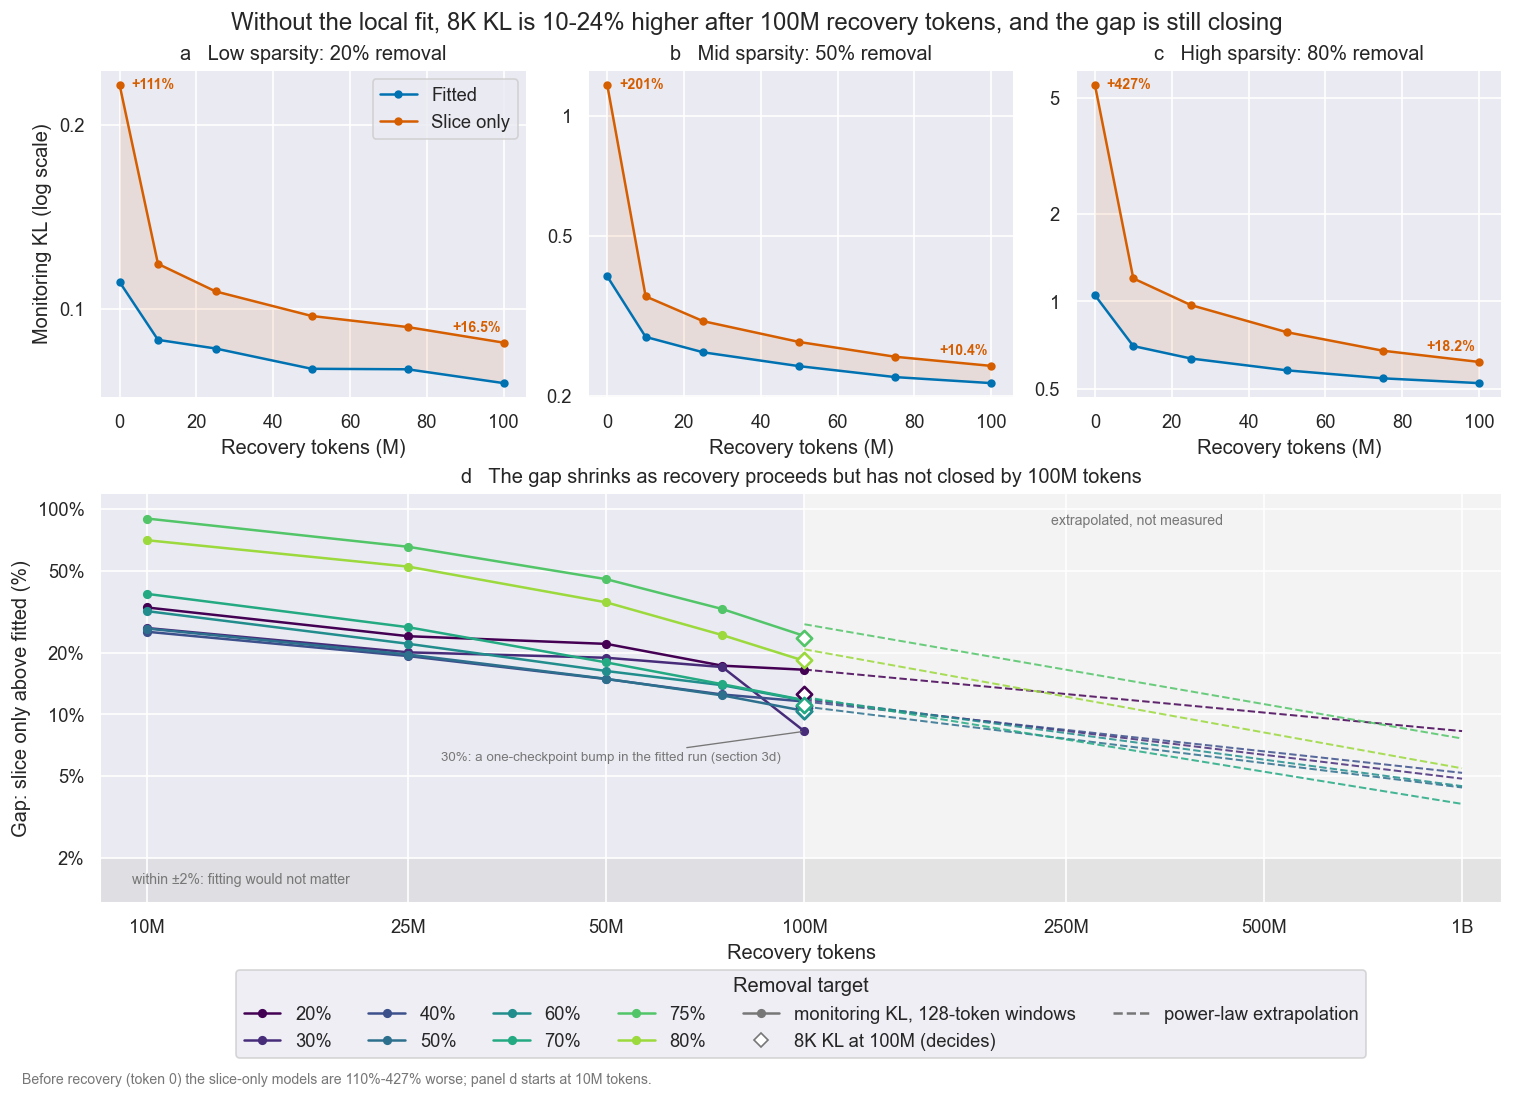

Target,Gap @ 0M,Gap @ 10M,Gap @ 25M,Gap @ 50M,Gap @ 75M,Gap @ 100M,8K KL gap @ 100M,Extrapolated @ 1B
20%,+110.6%,+33.2%,+24.1%,+22.1%,+17.3%,+16.5%,+12.6%,+8.3%
30%,+109.8%,+26.4%,+20.1%,+18.9%,+17.0%,+8.3%,+10.9%,+4.9%
40%,+143.1%,+25.3%,+19.2%,+14.9%,+12.5%,+11.6%,+10.7%,+5.2%
50%,+200.6%,+26.2%,+19.6%,+14.9%,+12.4%,+10.4%,+10.4%,+4.4%
60%,+301.4%,+31.9%,+22.1%,+16.3%,+13.9%,+11.7%,+10.4%,+4.5%
70%,+364.4%,+38.7%,+26.6%,+17.9%,+14.0%,+11.7%,+11.1%,+3.7%
75%,+425.3%,+90.2%,+65.6%,+45.6%,+32.7%,+24.1%,+23.5%,+7.6%
80%,+427.3%,+70.7%,+52.5%,+35.2%,+24.4%,+18.2%,+18.4%,+5.5%


In [8]:
history_df = pd.DataFrame([
    {
        'Arm': arm, 'Target': target, 'Tokens': requested_tokens(row), 'Actual tokens': row['actual_tokens'],
        'Monitoring KL': row['recovery_validation_kl'],
        'Monitoring PPL': (row.get('wikitext_validation') or {}).get('perplexity'),
    }
    for (arm, target), run in runs.items() for row in run['results']['recovery']['validation_history']
])
gap_df = history_df.pivot_table(index=['Target', 'Tokens'], columns='Arm', values='Monitoring KL').reset_index()
gap_df['Gap'] = gap_df['slice'] / gap_df['fitted'] - 1

final_df = pd.DataFrame([
    {
        'Arm': arm, 'Target': target,
        'Eligible-MLP removal': prepared_results['starts'][f'{arm}:{target}']['realized_eligible_mlp_removal'],
        'Whole-model removal': evaluation['footprint']['whole_model_parameter_removal'],
        'Parameters': evaluation['footprint']['parameters'],
        'Bundle GiB': evaluation['footprint']['bundle_bytes'] / 2**30,
        'KL @ 8K': evaluation['teacher_kl_8192']['kl'],
        **{f'PPL @ {context:,}': evaluation['likelihood'][f'test-{context}']['perplexity'] for context in (128, 2048, 8192)},
        'Macro accuracy': evaluation['comparison_to_dense']['macro_accuracy'],
        **{label: evaluation['comparison_to_dense']['tasks'][task]['student'] for task, label in TASKS.items()},
    }
    for (arm, target), run in runs.items() for evaluation in [run['results']['evaluation']]
]).sort_values(['Target', 'Arm'], ignore_index=True)
final_kl = final_df.pivot(index='Target', columns='Arm', values='KL @ 8K')
final_gap = final_kl['slice'] / final_kl['fitted'] - 1

extrapolation_rows = []
for target, rows in gap_df[gap_df['Tokens'] > 0].groupby('Target'):
    slope, intercept = np.polyfit(np.log(rows['Tokens']), np.log(rows['Gap']), 1)
    extrapolation_rows.append({
        'Target': target, 'Slope': slope, 'Intercept': intercept,
        'Gap @ 1B (extrapolated)': np.exp(intercept + slope * np.log(EXTRAPOLATION_TOKENS)),
    })
extrapolation_df = pd.DataFrame(extrapolation_rows).set_index('Target')

figure = plt.figure(figsize=(12.5, 8.8))
grid = figure.add_gridspec(2, 3, height_ratios=(1, 1.25))
trajectory_axes = [figure.add_subplot(grid[0, column]) for column in range(3)]
gap_axis = figure.add_subplot(grid[1, :])
for axis, letter, (target, level) in zip(trajectory_axes, 'abc', SHOWCASE_TARGETS.items()):
    rows = gap_df[gap_df['Target'] == target]
    tokens = rows['Tokens'] / 1e6
    axis.fill_between(tokens, rows['fitted'], rows['slice'], color=ARM_COLORS['slice'], alpha=0.10, linewidth=0)
    for arm in ARMS:
        axis.plot(tokens, rows[arm], color=ARM_COLORS[arm], marker='o', markersize=4, label=ARM_LABELS[arm])
    for row, offset, alignment in ((rows.iloc[0], (7, 0), 'left'), (rows.iloc[-1], (-2, 9), 'right')):
        axis.annotate(f"{row['Gap']:+.0%}" if row['Tokens'] == 0 else f"{row['Gap']:+.1%}",
                      (row['Tokens'] / 1e6, row['slice']), xytext=offset, textcoords='offset points',
                      ha=alignment, va='center', fontsize=8.5, fontweight='bold', color=ARM_COLORS['slice'])
    axis.set(yscale='log', xlim=(-5, 106), xlabel='Recovery tokens (M)',
             title=f'{letter}   {level} sparsity: {target:.0%} removal')
    axis.yaxis.set_major_locator(LogLocator(base=10, subs=(1.0, 2.0, 5.0)))
    axis.yaxis.set_major_formatter(FuncFormatter(lambda value, _: f'{value:g}'))
    axis.yaxis.set_minor_formatter(NullFormatter())
trajectory_axes[0].set_ylabel('Monitoring KL (log scale)')
trajectory_axes[0].legend(loc='upper right')

measured = gap_df[gap_df['Tokens'] > 0]
gap_axis.axvspan(1e8, EXTRAPOLATION_TOKENS * 1.15, color='#f3f3f3', linewidth=0, zorder=0)
gap_axis.axhspan(0.5, 100 * GAP_THRESHOLD, color='#d9d9d9', alpha=0.6, linewidth=0, zorder=0)
for target, rows in measured.groupby('Target'):
    color = TARGET_COLORS[target]
    gap_axis.plot(rows['Tokens'], 100 * rows['Gap'], color=color, marker='o', markersize=4.5, zorder=3)
    fit = extrapolation_df.loc[target]
    future = np.geomspace(rows['Tokens'].max(), EXTRAPOLATION_TOKENS, 40)
    gap_axis.plot(future, 100 * np.exp(fit['Intercept'] + fit['Slope'] * np.log(future)), color=color,
                  linestyle='--', linewidth=1.2, alpha=0.85, zorder=2)
    gap_axis.scatter(1e8, 100 * final_gap[target], marker='D', s=42, facecolor='white', edgecolor=color,
                     linewidth=1.6, zorder=4)
bump = measured[(measured['Target'] == 0.3) & (measured['Tokens'] == 100_000_000)].iloc[0]
gap_axis.annotate('30%: a one-checkpoint bump in the fitted run (section 3d)', (bump['Tokens'], 100 * bump['Gap']),
                  xytext=(-14, -18), textcoords='offset points', ha='right', fontsize=8, color=NOTE_COLOR,
                  arrowprops={'arrowstyle': '-', 'color': NOTE_COLOR, 'linewidth': 0.8})
token_ticks = [1e7, 2.5e7, 5e7, 1e8, 2.5e8, 5e8, 1e9]
gap_axis.set(xscale='log', yscale='log', xlim=(8.5e6, EXTRAPOLATION_TOKENS * 1.15), ylim=(1.2, 120),
             xlabel='Recovery tokens', ylabel='Gap: slice only above fitted (%)',
             title='d   The gap shrinks as recovery proceeds but has not closed by 100M tokens')
gap_axis.xaxis.set_major_locator(FixedLocator(token_ticks))
gap_axis.xaxis.set_major_formatter(FuncFormatter(lambda value, _: f'{value / 1e9:g}B' if value >= 1e9 else f'{value / 1e6:g}M'))
gap_axis.xaxis.set_minor_locator(NullLocator())
gap_axis.yaxis.set_major_locator(FixedLocator([2, 5, 10, 20, 50, 100]))
gap_axis.yaxis.set_major_formatter(FuncFormatter(lambda value, _: f'{value:g}%'))
gap_axis.yaxis.set_minor_locator(NullLocator())
gap_axis.text(3.2e8, 95, 'extrapolated, not measured', color=NOTE_COLOR, fontsize=8.5, ha='center', va='top')
gap_axis.text(9.5e6, 1.45, f'within ±{GAP_THRESHOLD:.0%}: fitting would not matter', color=NOTE_COLOR,
              fontsize=8.5, va='bottom')
gap_axis.legend(handles=[
    *(Line2D([], [], color=TARGET_COLORS[target], marker='o', markersize=4.5, label=f'{target:.0%}') for target in TARGETS),
    Line2D([], [], color=NOTE_COLOR, marker='o', markersize=4.5, label='monitoring KL, 128-token windows'),
    Line2D([], [], color=NOTE_COLOR, marker='D', markerfacecolor='white', linestyle='none', label='8K KL at 100M (decides)'),
    Line2D([], [], color=NOTE_COLOR, linestyle='--', label='power-law extrapolation'),
], ncol=6, loc='upper center', bbox_to_anchor=(0.5, -0.14), title='Removal target')
figure.suptitle(
    f'Without the local fit, 8K KL is {100 * final_gap.min():.0f}-{100 * final_gap.max():.0f}% higher after 100M '
    'recovery tokens, and the gap is still closing',
)
first_gaps = gap_df[gap_df['Tokens'] == 0]['Gap']
figure.text(0.01, -0.02, f'Before recovery (token 0) the slice-only models are {first_gaps.min():.0%}-{first_gaps.max():.0%} '
            'worse; panel d starts at 10M tokens.', fontsize=8.5, color=NOTE_COLOR)
plt.show()

trajectory_table = gap_df.pivot(index='Target', columns='Tokens', values='Gap')
trajectory_table.columns = [f'Gap @ {tokens / 1e6:.0f}M' for tokens in trajectory_table.columns]
trajectory_table['8K KL gap @ 100M'] = final_gap
trajectory_table['Extrapolated @ 1B'] = extrapolation_df['Gap @ 1B (extrapolated)']
show_table(trajectory_table.reset_index(), 'Gap (slice - fitted) / fitted: monitoring KL by tokens, 8K KL at 100M, '
           'and the power-law extrapolation (not measured)',
           {'Target': '{:.0%}'} | {column: '{:+.1%}' for column in trajectory_table.columns})

##### b. What the local fit is worth in recovery tokens

The gap at a fixed budget says how much better the fitted model is at 100M. A fixed-quality view answers the practical question: how many tokens does the fitted model need to reach the slice-only model's 100M monitoring KL? The crossing point is interpolated on log tokens between the fitted run's checkpoints. With one run per arm and checkpoint noise of up to 3.5%, it is approximate.

The local-fit time is the sum of the recorded fit seconds for the layer widths that each target uses. It excludes the shared activation capture, so it is a lower bound. Recovery time uses each slice-only run's measured training throughput.

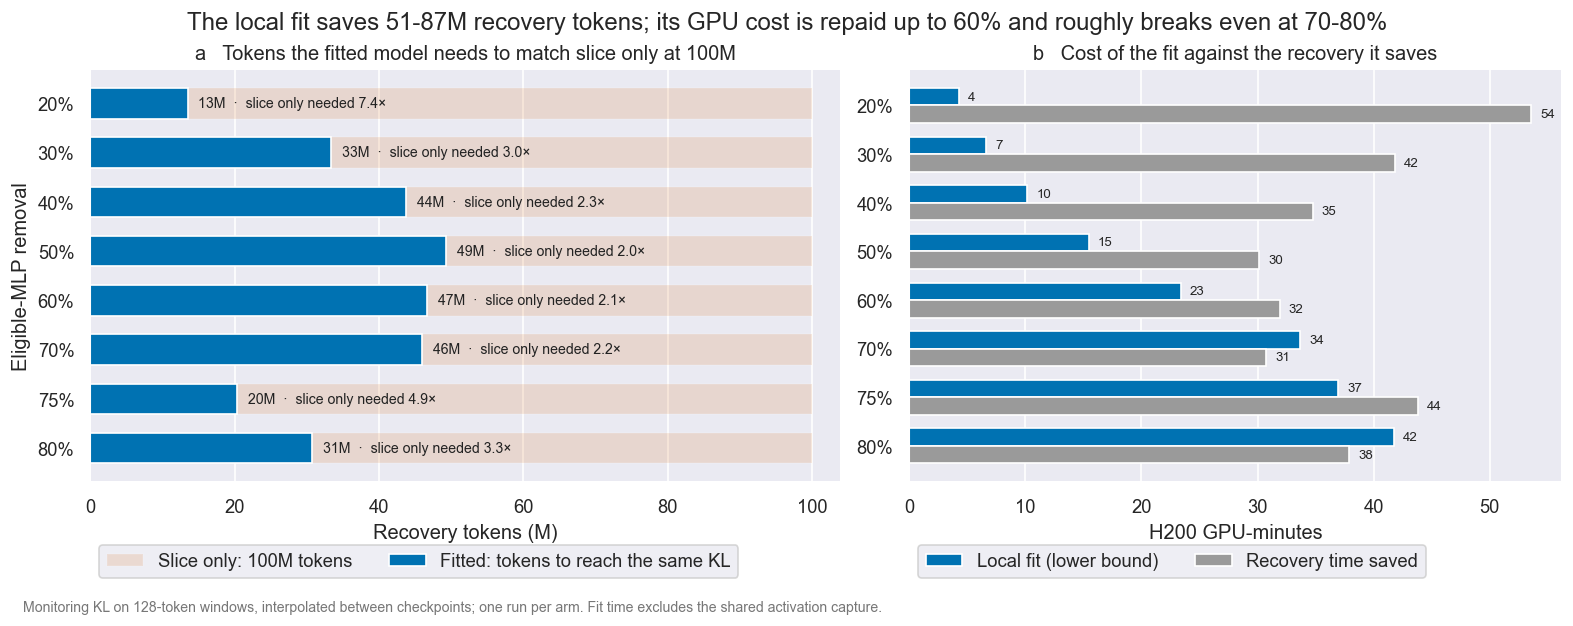

Target,Fitted tokens to match (M),Tokens saved (M),Slice-only token multiple,Local fit (GPU-min),Recovery saved (GPU-min)
20%,13.5,86.5,7.4×,4.3,53.5
30%,33.3,66.7,3.0×,6.6,41.8
40%,43.7,56.3,2.3×,10.1,34.7
50%,49.3,50.7,2.0×,15.5,30.1
60%,46.6,53.4,2.1×,23.4,31.9
70%,46.0,54.0,2.2×,33.7,30.7
75%,20.3,79.7,4.9×,36.9,43.8
80%,30.7,69.3,3.3×,41.7,37.9


In [9]:
fit_seconds = {(fit['layer'], fit['replacement_width']): fit['fit_seconds'] for fit in prepared_results['local_fitting']}
worth_rows = []
for target in TARGETS:
    fitted_rows = history_df[(history_df['Arm'] == 'fitted') & (history_df['Target'] == target)].sort_values('Tokens')
    slice_final = history_df[(history_df['Arm'] == 'slice') & (history_df['Target'] == target)].sort_values('Tokens').iloc[-1]
    tokens = fitted_rows['Actual tokens'].to_numpy(dtype=float)
    kl = fitted_rows['Monitoring KL'].to_numpy()
    reached = np.flatnonzero(kl <= slice_final['Monitoring KL'])
    index = reached[0]  # first checkpoint at or below the slice-only 100M value
    fraction = (kl[index - 1] - slice_final['Monitoring KL']) / (kl[index - 1] - kl[index])
    if tokens[index - 1] > 0:
        equivalent = np.exp(np.log(tokens[index - 1]) + fraction * (np.log(tokens[index]) - np.log(tokens[index - 1])))
    else:
        equivalent = tokens[index - 1] + fraction * (tokens[index] - tokens[index - 1])
    allocation = prepared_results['allocation']['targets'][str(target)]['allocation']
    recovery = runs[('slice', target)]['results']['recovery']
    seconds_per_token = recovery['training_seconds'] / recovery['tokens_seen']
    worth_rows.append({
        'Target': target,
        'Fitted tokens to match (M)': equivalent / 1e6,
        'Tokens saved (M)': (slice_final['Actual tokens'] - equivalent) / 1e6,
        'Slice-only token multiple': slice_final['Actual tokens'] / equivalent,
        'Local fit (GPU-min)': sum(fit_seconds[(row['layer'], row['replacement_width'])]
                                   for row in allocation if not row['retains_dense_module']) / 60,
        'Recovery saved (GPU-min)': (slice_final['Actual tokens'] - equivalent) * seconds_per_token / 60,
    })
worth_df = pd.DataFrame(worth_rows)

figure, (token_axis, cost_axis) = plt.subplots(1, 2, figsize=(13, 4.8), gridspec_kw={'width_ratios': (1.15, 1)})
positions = np.arange(len(worth_df))
token_axis.barh(positions, 100, color=ARM_COLORS['slice'], alpha=0.14, height=0.62, label='Slice only: 100M tokens')
token_axis.barh(positions, worth_df['Fitted tokens to match (M)'], color=ARM_COLORS['fitted'], height=0.62,
                label='Fitted: tokens to reach the same KL')
for position, row in worth_df.iterrows():
    token_axis.text(row['Fitted tokens to match (M)'] + 1.5, position,
                    f"{row['Fitted tokens to match (M)']:.0f}M  ·  slice only needed {row['Slice-only token multiple']:.1f}×",
                    va='center', fontsize=8.5, color='#222222')
token_axis.set(yticks=positions, yticklabels=[f'{target:.0%}' for target in worth_df['Target']], xlim=(0, 104),
               xlabel='Recovery tokens (M)', ylabel='Eligible-MLP removal',
               title='a   Tokens the fitted model needs to match slice only at 100M')
token_axis.invert_yaxis()
token_axis.grid(False)
token_axis.xaxis.grid(True)
token_axis.legend(loc='upper left', bbox_to_anchor=(0, -0.13), ncol=2)

height = 0.36
cost_axis.barh(positions - height / 2, worth_df['Local fit (GPU-min)'], height=height, color=ARM_COLORS['fitted'],
               label='Local fit (lower bound)')
cost_axis.barh(positions + height / 2, worth_df['Recovery saved (GPU-min)'], height=height, color='#9a9a9a',
               label='Recovery time saved')
for position, row in worth_df.iterrows():
    cost_axis.text(row['Local fit (GPU-min)'] + 0.8, position - height / 2, f"{row['Local fit (GPU-min)']:.0f}",
                   va='center', fontsize=8)
    cost_axis.text(row['Recovery saved (GPU-min)'] + 0.8, position + height / 2, f"{row['Recovery saved (GPU-min)']:.0f}",
                   va='center', fontsize=8)
cost_axis.set(yticks=positions, yticklabels=[f'{target:.0%}' for target in worth_df['Target']],
              xlabel='H200 GPU-minutes', title='b   Cost of the fit against the recovery it saves')
cost_axis.invert_yaxis()
cost_axis.grid(False)
cost_axis.xaxis.grid(True)
cost_axis.legend(loc='upper left', bbox_to_anchor=(0, -0.13), ncol=2)
figure.suptitle(
    f"The local fit saves {worth_df['Tokens saved (M)'].min():.0f}-{worth_df['Tokens saved (M)'].max():.0f}M "
    'recovery tokens; its GPU cost is repaid up to 60% and roughly breaks even at 70-80%',
)
figure.text(0.01, -0.05, 'Monitoring KL on 128-token windows, interpolated between checkpoints; one run per arm. '
            'Fit time excludes the shared activation capture.', fontsize=8.5, color=NOTE_COLOR)
plt.show()
show_table(worth_df, 'Fixed-quality comparison at the slice-only 100M monitoring KL',
           {'Target': '{:.0%}', 'Fitted tokens to match (M)': '{:.1f}', 'Tokens saved (M)': '{:.1f}',
            'Slice-only token multiple': '{:.1f}×', 'Local fit (GPU-min)': '{:.1f}', 'Recovery saved (GPU-min)': '{:.1f}'})

##### c. The verdict at 100M

The decided rule judges each target on the 8K KL gap at 100M and on whether the monitoring gap is still moving between 50M and 100M. Perplexity and task accuracy are secondary. There is no paired between-arm interval for the tasks; the per-task intervals in the artifacts compare each model with the dense teacher.

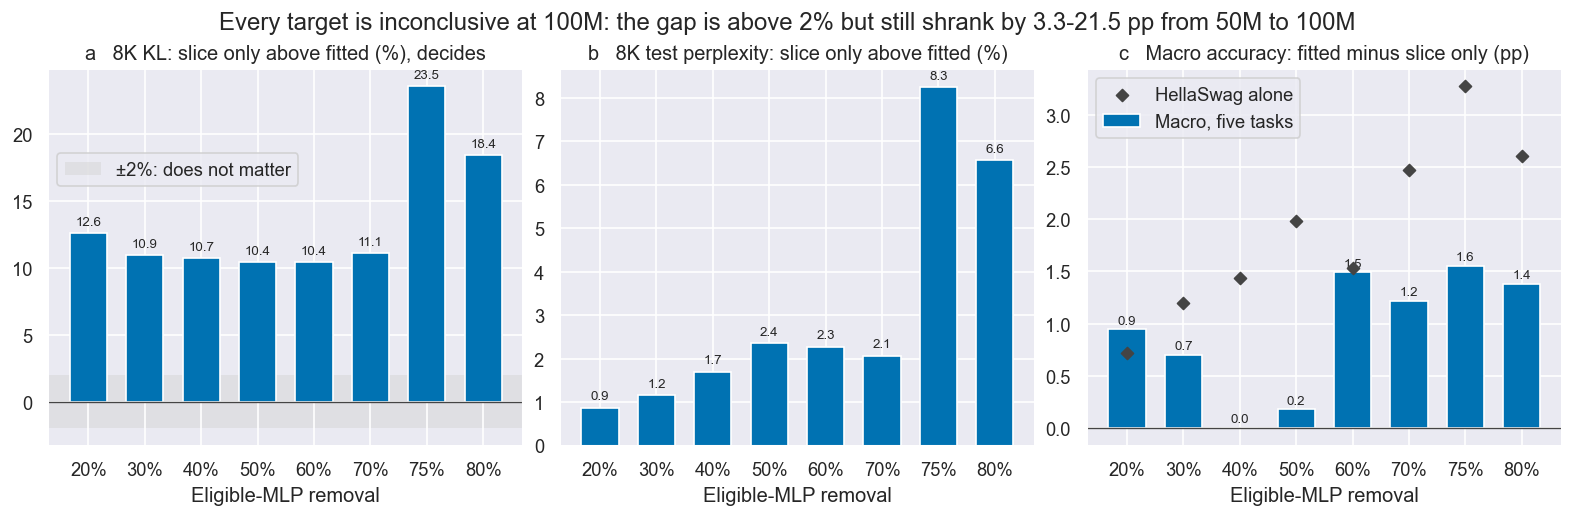

Target,8K KL gap,Monitoring gap @ 50M,Monitoring gap @ 100M,Change 50M→100M (pp),Stable,Conclusion,PPL @ 8K gap,Macro fitted - slice (pp),HellaSwag fitted - slice (pp)
20%,+12.6%,+22.1%,+16.5%,-5.6,False,Inconclusive at 100M,+0.9%,+0.94,+0.72
30%,+10.9%,+18.9%,+8.3%,-10.6,False,Inconclusive at 100M,+1.2%,+0.70,+1.19
40%,+10.7%,+14.9%,+11.6%,-3.3,False,Inconclusive at 100M,+1.7%,-0.01,+1.43
50%,+10.4%,+14.9%,+10.4%,-4.5,False,Inconclusive at 100M,+2.4%,+0.18,+1.98
60%,+10.4%,+16.3%,+11.7%,-4.6,False,Inconclusive at 100M,+2.3%,+1.49,+1.53
70%,+11.1%,+17.9%,+11.7%,-6.2,False,Inconclusive at 100M,+2.1%,+1.22,+2.47
75%,+23.5%,+45.6%,+24.1%,-21.5,False,Inconclusive at 100M,+8.3%,+1.55,+3.28
80%,+18.4%,+35.2%,+18.2%,-16.9,False,Inconclusive at 100M,+6.6%,+1.38,+2.61


In [10]:
verdict_rows = []
for target in TARGETS:
    monitoring = gap_df[gap_df['Target'] == target].set_index('Tokens')['Gap']
    gap = final_gap[target]
    change = monitoring.loc[100_000_000] - monitoring.loc[50_000_000]
    stable = abs(change) < STABILITY_THRESHOLD
    if abs(gap) <= GAP_THRESHOLD:
        conclusion = 'Fitting does not matter after recovery'
    elif stable:
        conclusion = 'Fitting matters' if gap > 0 else 'Fitting hurts (slice only is better)'
    else:
        conclusion = 'Inconclusive at 100M'
    values = final_df[final_df['Target'] == target].set_index('Arm')
    verdict_rows.append({
        'Target': target,
        '8K KL gap': gap,
        'Monitoring gap @ 50M': monitoring.loc[50_000_000],
        'Monitoring gap @ 100M': monitoring.loc[100_000_000],
        'Change 50M→100M (pp)': 100 * change,
        'Stable': stable,
        'Conclusion': conclusion,
        'PPL @ 8K gap': values.loc['slice', 'PPL @ 8,192'] / values.loc['fitted', 'PPL @ 8,192'] - 1,
        'Macro fitted - slice (pp)': 100 * (values.loc['fitted', 'Macro accuracy'] - values.loc['slice', 'Macro accuracy']),
        'HellaSwag fitted - slice (pp)': 100 * (values.loc['fitted', 'HellaSwag'] - values.loc['slice', 'HellaSwag']),
    })
verdict_df = pd.DataFrame(verdict_rows)

figure, axes = plt.subplots(1, 3, figsize=(13, 4.2))
positions = np.arange(len(verdict_df))
labels = [f'{target:.0%}' for target in verdict_df['Target']]
panels = (
    ('8K KL gap', 100, 'a   8K KL: slice only above fitted (%), decides', True),
    ('PPL @ 8K gap', 100, 'b   8K test perplexity: slice only above fitted (%)', False),
    ('Macro fitted - slice (pp)', 1, 'c   Macro accuracy: fitted minus slice only (pp)', False),
)
for axis, (column, scale, title, band) in zip(axes, panels):
    values = scale * verdict_df[column]
    axis.bar(positions, values, color=[ARM_COLORS['fitted'] if value >= 0 else ARM_COLORS['slice'] for value in values],
             width=0.66, label='Macro, five tasks' if column.startswith('Macro') else None)
    pad = 0.015 * values.abs().max()
    for position, value in zip(positions, values):
        shown = 0.0 if abs(value) < 0.05 else value
        axis.text(position, shown + (pad if shown >= 0 else -pad), f'{shown:.1f}', ha='center',
                  va='bottom' if shown >= 0 else 'top', fontsize=8)
    if band:
        axis.axhspan(-100 * GAP_THRESHOLD, 100 * GAP_THRESHOLD, color='#d9d9d9', alpha=0.6, linewidth=0, zorder=0,
                     label=f'±{GAP_THRESHOLD:.0%}: does not matter')
        axis.legend(loc='upper left', bbox_to_anchor=(0, 0.8))
    axis.axhline(0, color=DENSE_COLOR, linewidth=0.8)
    axis.set(xticks=positions, xticklabels=labels, xlabel='Eligible-MLP removal', title=title)
axes[2].scatter(positions, verdict_df['HellaSwag fitted - slice (pp)'], marker='D', s=26, color=DENSE_COLOR,
                zorder=4, label='HellaSwag alone')
axes[2].legend(loc='upper left')
conclusions = verdict_df['Conclusion'].value_counts()
headline = (f"Every target is {conclusions.index[0][0].lower()}{conclusions.index[0][1:]}" if len(conclusions) == 1
            else '; '.join(f'{count} × {name}' for name, count in conclusions.items()))
changes = verdict_df['Change 50M→100M (pp)']
figure.suptitle(
    f'{headline}: the gap is above {GAP_THRESHOLD:.0%} but still shrank by '
    f'{-changes.max():.1f}-{-changes.min():.1f} pp from 50M to 100M',
)
plt.show()
show_table(
    verdict_df,
    f'Decided rule: |g| ≤ {GAP_THRESHOLD:.0%} → does not matter; g > {GAP_THRESHOLD:.0%} and a stable monitoring gap '
    f'(change below {100 * STABILITY_THRESHOLD:.0f} pp) → matters; otherwise inconclusive at 100M',
    {'Target': '{:.0%}', '8K KL gap': '{:+.1%}', 'Monitoring gap @ 50M': '{:+.1%}', 'Monitoring gap @ 100M': '{:+.1%}',
     'Change 50M→100M (pp)': '{:+.1f}', 'PPL @ 8K gap': '{:+.1%}', 'Macro fitted - slice (pp)': '{:+.2f}',
     'HellaSwag fitted - slice (pp)': '{:+.2f}'},
)

##### d. Is the gap larger than run-to-run noise?

SwiGLU-8 has no repeat run per arm (decision log, 2026-10-10), but two comparisons bound the noise. The fitted 20-50% runs repeat SwiGLU-7's S7-0 runs with the same recipe, data and seed (check B2). Their first attempts, stopped at 10-25M tokens by the original 1e-3 check, repeat the reruns exactly. 8K-sequence training on PERUN GPUs is not bitwise repeatable, so both comparisons differ slightly.

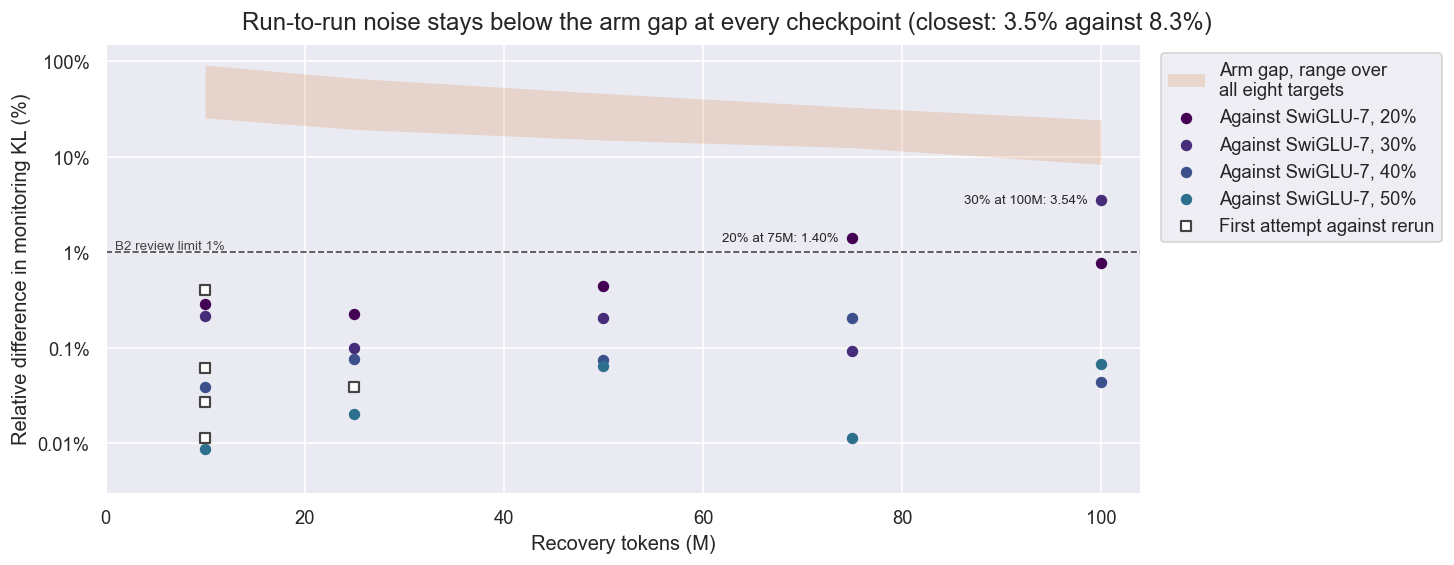

Comparison,Metric,Values,Median,Largest,Above 1%
Against SwiGLU-7 (B2),recovery_validation_kl,20,0.096%,3.542%,2
Against SwiGLU-7 (B2),wikitext_validation_perplexity,16,0.049%,0.187%,0
First attempt against rerun,recovery_validation_kl,5,0.039%,0.404%,0


In [11]:
noise_rows = []
for target in REPRODUCTION_TARGETS:
    for check in runs[('fitted', target)]['results']['acceptance']['B2']['checks']:
        noise_rows.append({'Comparison': 'Against SwiGLU-7 (B2)', 'Target': target, 'Metric': check['metric'],
                           'Tokens': check['tokens'], 'Difference': check['relative_difference']})
    rerun = {requested_tokens(row): row for row in runs[('fitted', target)]['results']['recovery']['validation_history']}
    for row in first_attempts[target]['results']['recovery']['validation_history']:
        if requested_tokens(row) == 0:
            continue
        noise_rows.append({
            'Comparison': 'First attempt against rerun', 'Target': target, 'Metric': 'recovery_validation_kl',
            'Tokens': row['actual_tokens'],
            'Difference': abs(row['recovery_validation_kl'] / rerun[requested_tokens(row)]['recovery_validation_kl'] - 1),
        })
noise_df = pd.DataFrame(noise_rows)
kl_noise = noise_df[noise_df['Metric'] == 'recovery_validation_kl']
gap_range = gap_df[gap_df['Tokens'] > 0].groupby('Tokens')['Gap'].agg(['min', 'max'])

figure, axis = plt.subplots(figsize=(12, 4.6))
axis.fill_between(gap_range.index / 1e6, 100 * gap_range['min'], 100 * gap_range['max'], color=ARM_COLORS['slice'],
                  alpha=0.16, linewidth=0, label='Arm gap, range over\nall eight targets')
axis.axhline(100 * REVIEW_LIMIT, color=DENSE_COLOR, linestyle='--', linewidth=1)
axis.text(1, 100 * REVIEW_LIMIT, f'B2 review limit {REVIEW_LIMIT:.0%}', fontsize=8, color=DENSE_COLOR, va='bottom')
for target in REPRODUCTION_TARGETS:
    rows = kl_noise[(kl_noise['Target'] == target) & (kl_noise['Comparison'] == 'Against SwiGLU-7 (B2)')]
    axis.scatter(rows['Tokens'] / 1e6, 100 * rows['Difference'], color=TARGET_COLORS[target], s=34, zorder=3,
                 label=f'Against SwiGLU-7, {target:.0%}')
repeats = kl_noise[kl_noise['Comparison'] == 'First attempt against rerun']
axis.scatter(repeats['Tokens'] / 1e6, 100 * repeats['Difference'], marker='s', facecolor='white',
             edgecolor=DENSE_COLOR, s=36, linewidth=1.3, zorder=4, label='First attempt against rerun')
for _, row in kl_noise[kl_noise['Difference'] > REVIEW_LIMIT].iterrows():
    axis.annotate(f"{row['Target']:.0%} at {row['Tokens'] / 1e6:.0f}M: {row['Difference']:.2%}",
                  (row['Tokens'] / 1e6, 100 * row['Difference']), xytext=(-8, 0), textcoords='offset points',
                  ha='right', va='center', fontsize=8)
axis.set(yscale='log', xlim=(0, 104), ylim=(0.003, 150), xlabel='Recovery tokens (M)',
         ylabel='Relative difference in monitoring KL (%)')
axis.yaxis.set_major_locator(FixedLocator([0.01, 0.1, 1, 10, 100]))
axis.yaxis.set_major_formatter(FuncFormatter(lambda value, _: f'{value:g}%'))
axis.yaxis.set_minor_locator(NullLocator())
axis.legend(loc='upper left', bbox_to_anchor=(1.01, 1.0))
smallest_gap = gap_range.loc[100_000_000, 'min']
figure.suptitle(
    f"Run-to-run noise stays below the arm gap at every checkpoint (closest: {kl_noise['Difference'].max():.1%} "
    f'against {smallest_gap:.1%})',
)
plt.show()
show_table(
    noise_df.groupby(['Comparison', 'Metric']).agg(
        Values=('Difference', 'size'), Median=('Difference', 'median'), Largest=('Difference', 'max'),
        **{'Above 1%': ('Difference', lambda values: int((values > REVIEW_LIMIT).sum()))},
    ).reset_index(),
    'Run-to-run differences (fitted 20-50%)',
    {'Median': '{:.3%}', 'Largest': '{:.3%}'},
)

#### 4. Context length

Context length enters the pipeline three times. The local fit trains on 128-token windows, recovery trains on 8,192-token sequences, and the models are evaluated at 128, 2,048 and 8,192 tokens. This section asks whether the mismatch matters.

##### a. Training context of the local fit

Part A trained every learning-rate and schedule combination on both 128-token and 8K-token activation pairs. Comparing each 8K setting with its 128-token twin isolates the effect of the training context for every layer and width.

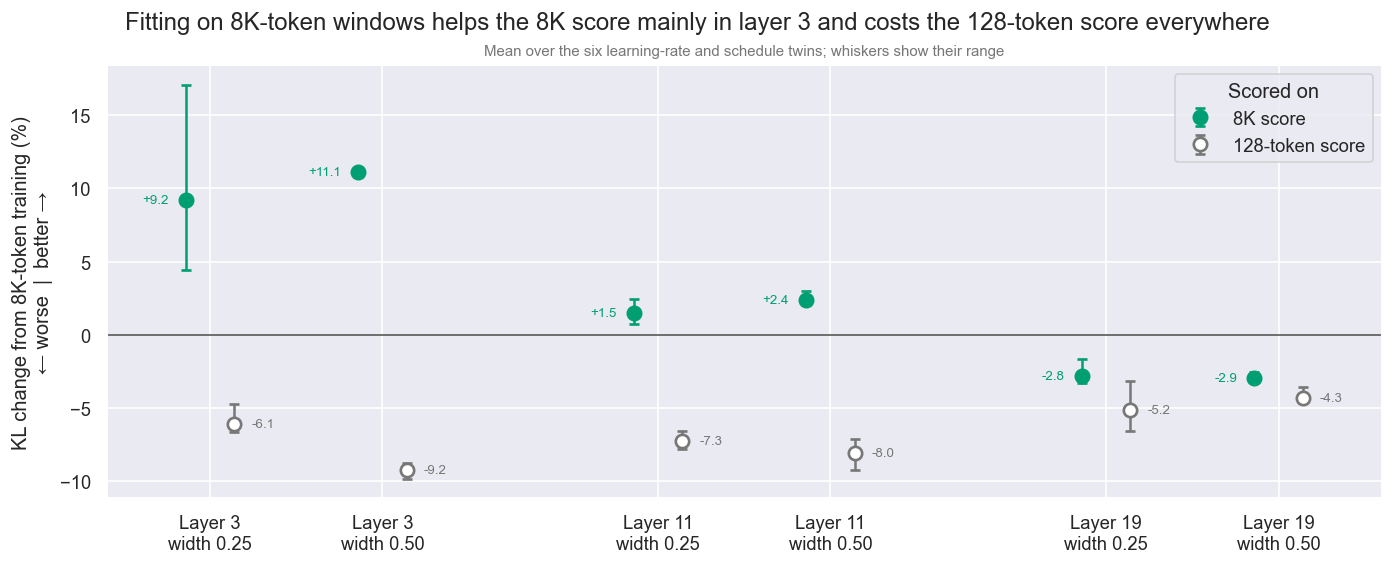

In [12]:
COMBINATIONS = sorted({(row['layer'], row['width_ratio']) for row in block_results['fits']})
seed_means = fits_df.groupby(['Setting', 'Layer', 'Width ratio'])[['KL @ 128', 'KL @ 8K']].mean()
context_df = pd.DataFrame([
    {
        'Pair': short, 'Layer': layer, 'Width ratio': width,
        'Change @ 8K': 1 - seed_means.loc[(short.replace('-128', '-8k'), layer, width), 'KL @ 8K']
        / seed_means.loc[(short, layer, width), 'KL @ 8K'],
        'Change @ 128': 1 - seed_means.loc[(short.replace('-128', '-8k'), layer, width), 'KL @ 128']
        / seed_means.loc[(short, layer, width), 'KL @ 128'],
    }
    for short in setting_grid if family(short) == '128-token windows'
    for layer, width in COMBINATIONS
])
context_summary = context_df.groupby(['Layer', 'Width ratio'])[['Change @ 8K', 'Change @ 128']].agg(['mean', 'min', 'max'])

figure, axis = plt.subplots(figsize=(11.5, 4.6))
positions = np.arange(len(COMBINATIONS)) + np.repeat(np.arange(len(COMBINATIONS) // 2) * 0.6, 2)
for column, offset, color, filled, label in (
    ('Change @ 8K', -0.14, '#009E73', True, '8K score'),
    ('Change @ 128', 0.14, NOTE_COLOR, False, '128-token score'),
):
    means = 100 * context_summary[(column, 'mean')].to_numpy()
    errors = [means - 100 * context_summary[(column, 'min')].to_numpy(), 100 * context_summary[(column, 'max')].to_numpy() - means]
    axis.errorbar(positions + offset, means, yerr=errors, fmt='o', color=color, markersize=8, capsize=3,
                  markerfacecolor=color if filled else 'white', markeredgewidth=1.6, label=label, zorder=3)
    for position, mean in zip(positions + offset, means):
        axis.text(position + (-0.1 if filled else 0.1), mean, f'{mean:+.1f}', ha='right' if filled else 'left',
                  va='center', fontsize=8, color=color)
axis.axhline(0, color=DENSE_COLOR, linewidth=0.9)
axis.set_xticks(positions, [f'Layer {layer}\nwidth {width:.2f}' for layer, width in COMBINATIONS])
axis.set(ylabel='KL change from 8K-token training (%)\n← worse  |  better →', xlim=(positions[0] - 0.6, positions[-1] + 0.6))
axis.legend(loc='upper right', title='Scored on')
axis.set_title('Mean over the six learning-rate and schedule twins; whiskers show their range', fontweight='normal',
               fontsize=9, color=NOTE_COLOR)
figure.suptitle('Fitting on 8K-token windows helps the 8K score mainly in layer 3 and costs the 128-token score everywhere')
plt.show()

##### b. Evaluation context of the recovered models

After recovery, both arms were scored on WikiText-2 test perplexity at three context lengths (stride half the context). They were also scored by KL against the teacher on the 128-token monitoring windows and on the 8K sequences.

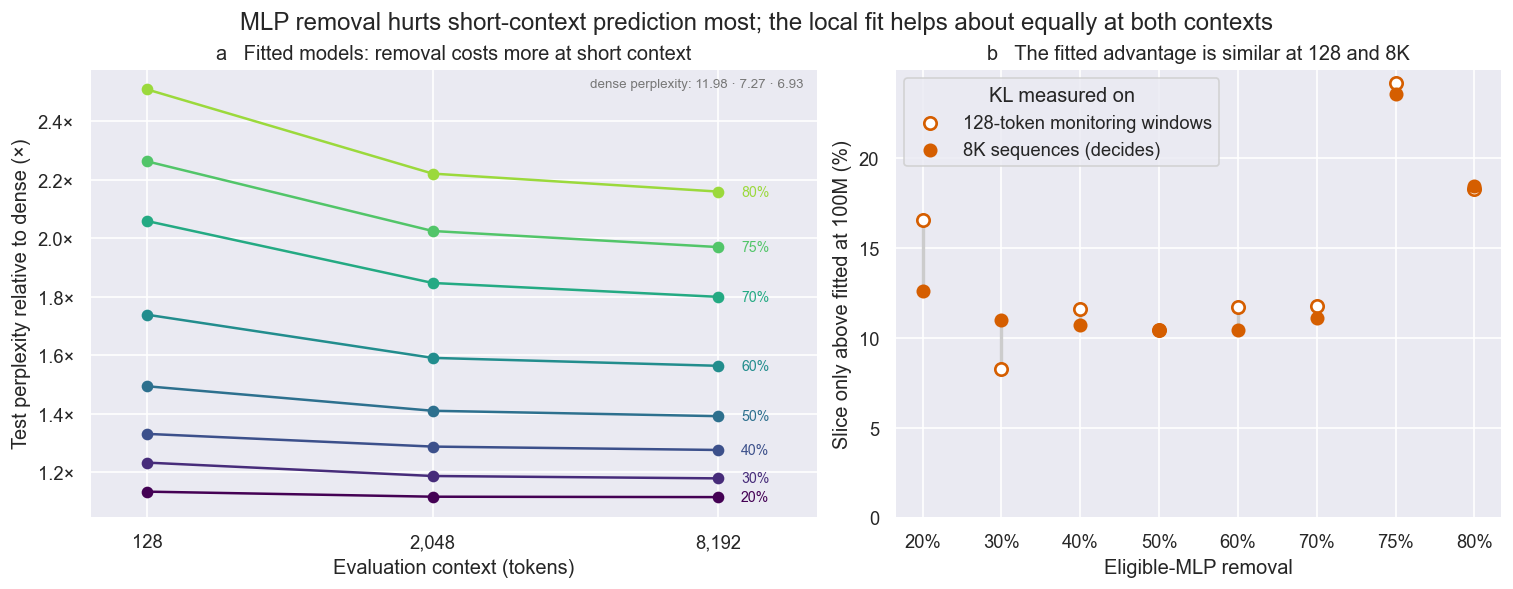

Target,Fitted / dense @ 128,"Fitted / dense @ 2,048","Fitted / dense @ 8,192",PPL gap @ 128,"PPL gap @ 2,048","PPL gap @ 8,192",KL gap @ 128 (monitoring),KL gap @ 8K
20%,1.133×,1.116×,1.114×,+1.0%,+0.9%,+0.9%,+16.5%,+12.6%
30%,1.232×,1.187×,1.178×,+1.3%,+1.2%,+1.2%,+8.3%,+10.9%
40%,1.331×,1.287×,1.276×,+2.4%,+1.8%,+1.7%,+11.6%,+10.7%
50%,1.493×,1.410×,1.391×,+2.0%,+2.5%,+2.4%,+10.4%,+10.4%
60%,1.738×,1.590×,1.563×,+0.7%,+2.4%,+2.3%,+11.7%,+10.4%
70%,2.059×,1.847×,1.799×,+0.1%,+1.8%,+2.1%,+11.7%,+11.1%
75%,2.263×,2.024×,1.969×,+9.2%,+8.0%,+8.3%,+24.1%,+23.5%
80%,2.509×,2.221×,2.159×,+7.8%,+6.6%,+6.6%,+18.2%,+18.4%


In [13]:
CONTEXTS = (128, 2048, 8192)
DENSE_PPL = {context: dense['likelihood'][f'test-{context}']['perplexity'] for context in CONTEXTS}
fitted_final = final_df[final_df['Arm'] == 'fitted'].set_index('Target')
slice_final = final_df[final_df['Arm'] == 'slice'].set_index('Target')
monitoring_gap = gap_df[gap_df['Tokens'] == 100_000_000].set_index('Target')['Gap']

figure, (ratio_axis, gap_axis) = plt.subplots(1, 2, figsize=(12.5, 4.8), gridspec_kw={'width_ratios': (1.2, 1)})
for target in TARGETS:
    ratios = [fitted_final.loc[target, f'PPL @ {context:,}'] / DENSE_PPL[context] for context in CONTEXTS]
    ratio_axis.plot(range(len(CONTEXTS)), ratios, color=TARGET_COLORS[target], marker='o')
    ratio_axis.text(len(CONTEXTS) - 0.92, ratios[-1], f'{target:.0%}', color=TARGET_COLORS[target], va='center', fontsize=8.5)
ratio_axis.set(xticks=range(len(CONTEXTS)), xticklabels=[f'{context:,}' for context in CONTEXTS],
               xlim=(-0.2, len(CONTEXTS) - 0.65), xlabel='Evaluation context (tokens)',
               ylabel='Test perplexity relative to dense (×)',
               title='a   Fitted models: removal costs more at short context')
ratio_axis.yaxis.set_major_formatter(FuncFormatter(lambda value, _: f'{value:.1f}×'))
ratio_axis.text(0.98, 0.98, 'dense perplexity: ' + ' · '.join(f'{DENSE_PPL[context]:.2f}' for context in CONTEXTS),
                transform=ratio_axis.transAxes, fontsize=8, color=NOTE_COLOR, ha='right', va='top')

positions = np.arange(len(TARGETS))
for position, target in zip(positions, TARGETS):
    gap_axis.plot([position, position], [100 * monitoring_gap[target], 100 * final_gap[target]], color='#cccccc',
                  linewidth=2, zorder=1)
gap_axis.scatter(positions, 100 * monitoring_gap.reindex(TARGETS), marker='o', s=55, facecolor='white',
                 edgecolor=ARM_COLORS['slice'], linewidth=1.6, zorder=3, label='128-token monitoring windows')
gap_axis.scatter(positions, 100 * final_gap.reindex(TARGETS), marker='o', s=55, color=ARM_COLORS['slice'], zorder=3,
                 label='8K sequences (decides)')
gap_axis.set(xticks=positions, xticklabels=[f'{target:.0%}' for target in TARGETS], ylim=(0, None),
             xlabel='Eligible-MLP removal', ylabel='Slice only above fitted at 100M (%)',
             title='b   The fitted advantage is similar at 128 and 8K')
gap_axis.legend(loc='upper left', title='KL measured on')
figure.suptitle('MLP removal hurts short-context prediction most; the local fit helps about equally at both contexts')
plt.show()

context_table = pd.DataFrame({
    **{f'Fitted / dense @ {context:,}': fitted_final[f'PPL @ {context:,}'] / DENSE_PPL[context] for context in CONTEXTS},
    **{f'PPL gap @ {context:,}': slice_final[f'PPL @ {context:,}'] / fitted_final[f'PPL @ {context:,}'] - 1
       for context in CONTEXTS},
    'KL gap @ 128 (monitoring)': monitoring_gap,
    'KL gap @ 8K': final_gap,
}).reset_index()
show_table(context_table, 'Test perplexity relative to dense, and slice-only gaps over fitted, by context at 100M',
           {'Target': '{:.0%}'} | {column: '{:.3f}×' for column in context_table.columns if 'dense' in column}
           | {column: '{:+.1%}' for column in context_table.columns if 'gap' in column})

**Observed.** Relative to the dense model, the compressed models lose more at 128 tokens than at 8,192 tokens at every target, and the gap grows with removal. The slice-only gap in KL is about the same on 128-token windows and 8K sequences. The perplexity gap is smaller than the KL gap at every context, with no consistent ordering across contexts.

**Interpretation (not tested here).** With more context, the untouched attention layers can recover more of the next-token prediction from earlier tokens, so the narrowed MLPs carry a smaller share of the work. A 128-token local fit does not leave a specific long-context deficit after recovery, which is consistent with Part A: training the fit at 8K buys little.

#### 5. The sparsity curve: the 20-80% control spectrum

The 16 runs are the homogeneous SwiGLU reference for the heterogeneous-operator chapter (decision log, 2026-10-10). Eligible-MLP removal counts only the 22 replaced MLPs. Whole-model removal counts all parameters, including embeddings and attention; it is shown on the top axis.

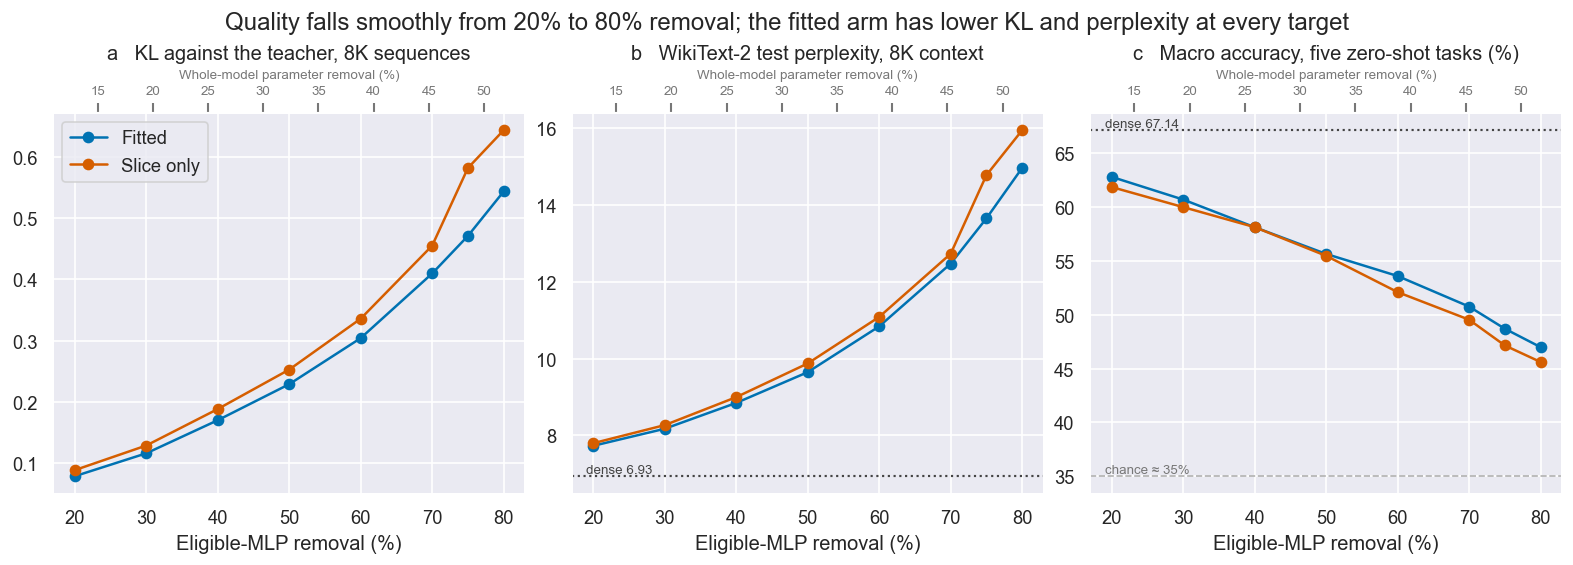

Target,Eligible-MLP removal,Whole-model removal,Parameters (M),Bundle GiB,"KL @ 8K, fitted","KL @ 8K, slice only","PPL @ 8,192, fitted","PPL @ 8,192, slice only","Macro accuracy, fitted","Macro accuracy, slice only"
20%,20.0%,12.9%,"1,490",2.78,0.0787,0.0887,7.73,7.79,62.80%,61.86%
30%,30.0%,19.4%,"1,379",2.57,0.1161,0.1288,8.17,8.26,60.70%,60.00%
40%,40.0%,25.9%,"1,268",2.37,0.1701,0.1883,8.84,8.99,58.13%,58.14%
50%,50.0%,32.4%,"1,158",2.16,0.2288,0.2527,9.64,9.87,55.65%,55.47%
60%,60.0%,38.8%,"1,047",1.95,0.3040,0.3357,10.84,11.09,53.60%,52.10%
70%,70.0%,45.3%,936,1.75,0.4094,0.4549,12.47,12.73,50.76%,49.54%
75%,75.0%,48.5%,881,1.64,0.4707,0.5815,13.65,14.78,48.70%,47.15%
80%,80.0%,51.8%,826,1.54,0.5433,0.6432,14.97,15.95,46.99%,45.61%


In [14]:
DENSE_MACRO = (runs[('fitted', TARGETS[0])]['results']['evaluation']['comparison_to_dense']['macro_accuracy']
               - runs[('fitted', TARGETS[0])]['results']['evaluation']['comparison_to_dense']['macro_delta'])
DENSE_ACCURACY = {label: runs[('fitted', TARGETS[0])]['results']['evaluation']['comparison_to_dense']['tasks'][task]['dense']
                  for task, label in TASKS.items()}
whole_per_eligible = (final_df['Whole-model removal'] / final_df['Eligible-MLP removal']).mean()

figure, axes = plt.subplots(1, 3, figsize=(13, 4.6))
panels = (
    ('KL @ 8K', 1, 'a   KL against the teacher, 8K sequences', None),
    ('PPL @ 8,192', 1, 'b   WikiText-2 test perplexity, 8K context', DENSE_PPL[8192]),
    ('Macro accuracy', 100, 'c   Macro accuracy, five zero-shot tasks (%)', 100 * DENSE_MACRO),
)
for axis, (metric, scale, title, dense_value) in zip(axes, panels):
    for arm in ARMS:
        rows = final_df[final_df['Arm'] == arm]
        axis.plot(100 * rows['Eligible-MLP removal'], scale * rows[metric], color=ARM_COLORS[arm], marker='o',
                  label=ARM_LABELS[arm])
    if dense_value is not None:
        axis.axhline(dense_value, color=DENSE_COLOR, linestyle=':', linewidth=1.3)
        axis.text(19, dense_value, f'dense {dense_value:.2f}', fontsize=8, color=DENSE_COLOR, va='bottom')
    top_axis = axis.secondary_xaxis('top', functions=(lambda value: value * whole_per_eligible,
                                                      lambda value: value / whole_per_eligible))
    top_axis.set_xlabel('Whole-model parameter removal (%)', fontsize=8, color=NOTE_COLOR)
    top_axis.tick_params(labelsize=8, colors=NOTE_COLOR)
    axis.set(xlabel='Eligible-MLP removal (%)', title=title, xlim=(17, 83))
chance = 100 * np.mean(list(CHANCE_ACCURACY.values()))
axes[2].axhline(chance, color='#b0b0b0', linestyle='--', linewidth=1)
axes[2].text(19, chance, f'chance ≈ {chance:.0f}%', fontsize=8, color=NOTE_COLOR, va='bottom')
axes[0].legend(loc='upper left')
figure.suptitle('Quality falls smoothly from 20% to 80% removal; the fitted arm has lower KL and perplexity at every target')
plt.show()

spectrum_df = final_df.pivot(index='Target', columns='Arm')
show_table(pd.DataFrame({
    'Eligible-MLP removal': spectrum_df['Eligible-MLP removal']['fitted'],
    'Whole-model removal': spectrum_df['Whole-model removal']['fitted'],
    'Parameters (M)': spectrum_df['Parameters']['fitted'] / 1e6,
    'Bundle GiB': spectrum_df['Bundle GiB']['fitted'],
    **{f'{metric}, {ARM_LABELS[arm].lower()}': spectrum_df[metric][arm]
       for metric in ('KL @ 8K', 'PPL @ 8,192', 'Macro accuracy') for arm in ARMS},
}).reset_index(), f"Control spectrum at 100M recovery tokens; dense: {dense['footprint']['parameters'] / 1e6:,.0f}M "
   f"parameters, test PPL @ 8,192 {DENSE_PPL[8192]:.3f}, macro accuracy {DENSE_MACRO:.2%}",
   {'Target': '{:.0%}', 'Eligible-MLP removal': '{:.1%}', 'Whole-model removal': '{:.1%}', 'Parameters (M)': '{:,.0f}',
    'Bundle GiB': '{:.2f}', 'KL @ 8K, fitted': '{:.4f}', 'KL @ 8K, slice only': '{:.4f}',
    'PPL @ 8,192, fitted': '{:.2f}', 'PPL @ 8,192, slice only': '{:.2f}',
    'Macro accuracy, fitted': '{:.2%}', 'Macro accuracy, slice only': '{:.2%}'})

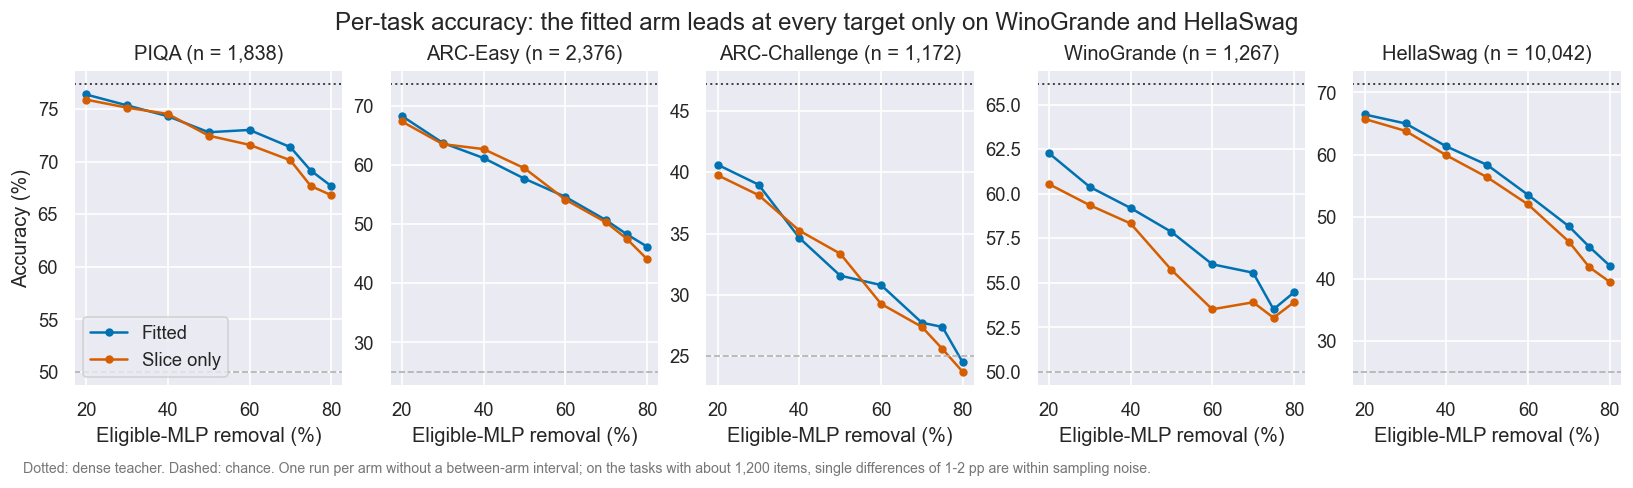

In [15]:
task_items = {task: row['examples'] for task, row in
              runs[('fitted', TARGETS[0])]['results']['evaluation']['comparison_to_dense']['tasks'].items()}
figure, axes = plt.subplots(1, len(TASKS), figsize=(13.5, 3.7), sharex=True)
for axis, (task, label) in zip(axes, TASKS.items()):
    for arm in ARMS:
        rows = final_df[final_df['Arm'] == arm]
        axis.plot(100 * rows['Eligible-MLP removal'], 100 * rows[label], color=ARM_COLORS[arm], marker='o',
                  markersize=4, label=ARM_LABELS[arm])
    axis.axhline(100 * DENSE_ACCURACY[label], color=DENSE_COLOR, linestyle=':', linewidth=1.2)
    axis.axhline(100 * CHANCE_ACCURACY[task], color='#b0b0b0', linestyle='--', linewidth=1)
    axis.set(title=f'{label} (n = {task_items[task]:,})', xlabel='Eligible-MLP removal (%)')
axes[0].set_ylabel('Accuracy (%)')
axes[0].legend(loc='lower left')
task_differences = {label: 100 * (final_df[final_df['Arm'] == 'fitted'][label].to_numpy()
                                  - final_df[final_df['Arm'] == 'slice'][label].to_numpy()) for label in TASKS.values()}
always_ahead = [label for label, values in task_differences.items() if (values > 0).all()]
figure.suptitle(
    'Per-task accuracy: ' + (f"the fitted arm leads at every target only on {' and '.join(always_ahead)}"
                             if always_ahead else 'no task separates the arms at every target'),
)
figure.text(0.01, -0.05, 'Dotted: dense teacher. Dashed: chance. One run per arm without a between-arm interval; on the '
            'tasks with about 1,200 items, single differences of 1-2 pp are within sampling noise.',
            fontsize=8.5, color=NOTE_COLOR)
plt.show()

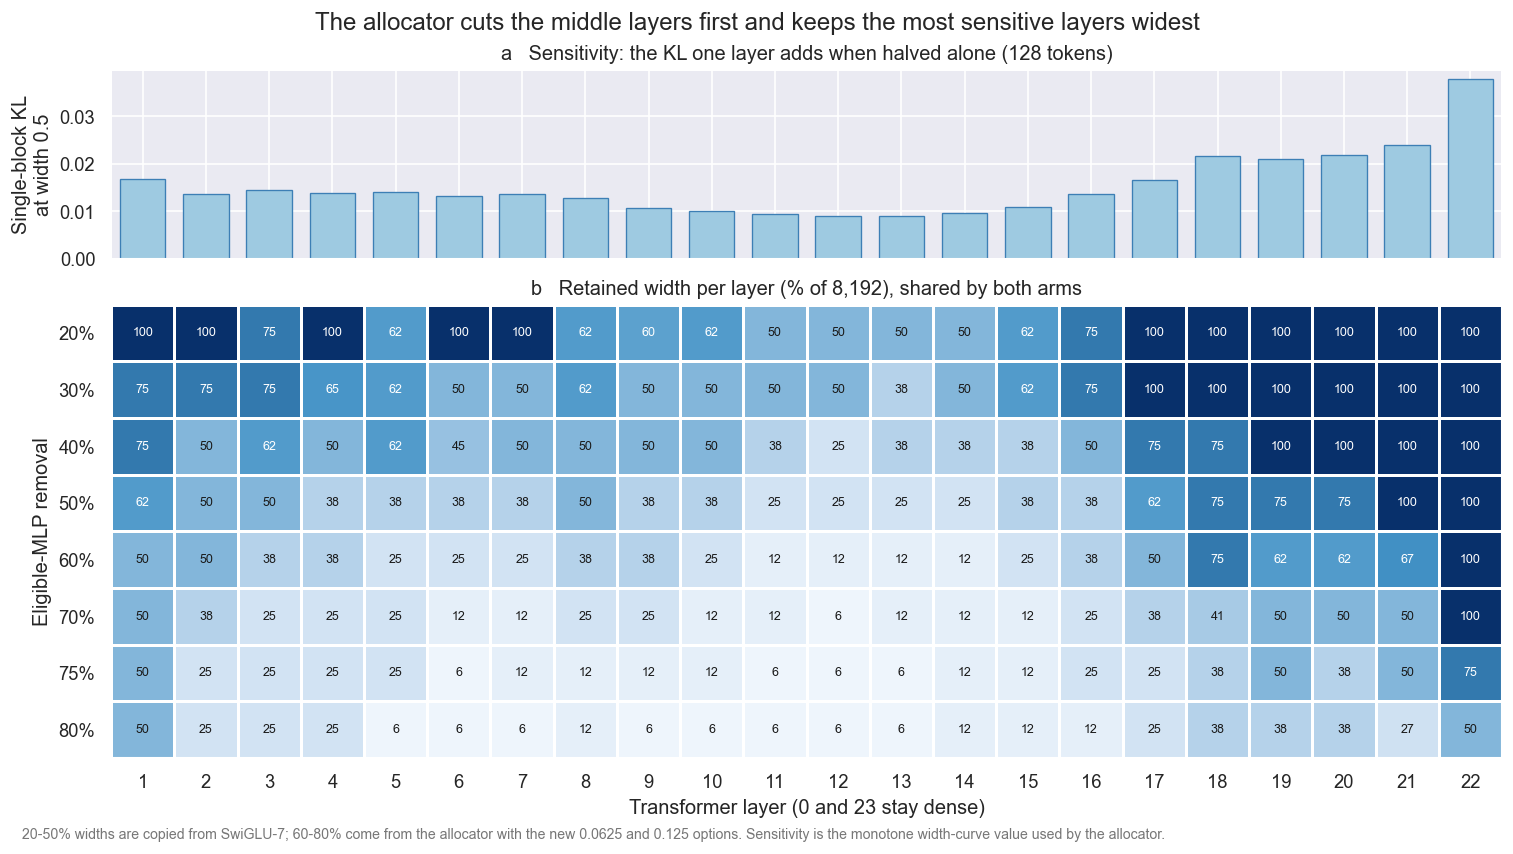

In [16]:
curve_rows = pd.DataFrame(prepared_results['width_curves']['rows'])
SENSITIVITY_WIDTH = ORIGINAL_WIDTH // 2
sensitivity = curve_rows[curve_rows['replacement_width'] == SENSITIVITY_WIDTH].set_index('layer')['monotone_teacher_kl']
width_matrix = pd.DataFrame([
    {'Target': float(target), 'Layer': row['layer'], 'Retained': row['replacement_width'] / row['original_width']}
    for target, entry in prepared_results['allocation']['targets'].items() for row in entry['allocation']
]).pivot(index='Target', columns='Layer', values='Retained').sort_index()
layers = width_matrix.columns.to_numpy()

figure, (bar_axis, map_axis) = plt.subplots(2, 1, figsize=(12.5, 6.8), sharex=True,
                                            gridspec_kw={'height_ratios': (1, 2.4)})
bar_axis.bar(layers, sensitivity.reindex(layers), color='#9ecae1', edgecolor='#3d7fb5', linewidth=0.8, width=0.72)
bar_axis.set(ylabel=f'Single-block KL\nat width {SENSITIVITY_WIDTH / ORIGINAL_WIDTH:.1f}',
             title='a   Sensitivity: the KL one layer adds when halved alone (128 tokens)')
retained_map = LinearSegmentedColormap.from_list('retained', ['#f7fbff', '#c6dbef', '#4292c6', '#08306b'])
map_axis.pcolormesh(np.append(layers - 0.5, layers[-1] + 0.5), np.arange(len(width_matrix) + 1), width_matrix.to_numpy(),
                    cmap=retained_map, vmin=0, vmax=1, edgecolors='white', linewidth=1.5)
for row_index, target in enumerate(width_matrix.index):
    for layer in layers:
        value = width_matrix.loc[target, layer]
        map_axis.text(layer, row_index + 0.5, f'{100 * value:.0f}', ha='center', va='center', fontsize=7.5,
                      color='white' if value > 0.55 else '#1a1a1a')
map_axis.set(yticks=np.arange(len(width_matrix)) + 0.5, yticklabels=[f'{target:.0%}' for target in width_matrix.index],
             xticks=layers, ylim=(len(width_matrix), 0), xlabel='Transformer layer (0 and 23 stay dense)',
             ylabel='Eligible-MLP removal', title='b   Retained width per layer (% of 8,192), shared by both arms')
map_axis.grid(False)
figure.suptitle('The allocator cuts the middle layers first and keeps the most sensitive layers widest')
figure.text(0.01, -0.02, '20-50% widths are copied from SwiGLU-7; 60-80% come from the allocator with the new 0.0625 '
            'and 0.125 options. Sensitivity is the monotone width-curve value used by the allocator.',
            fontsize=8.5, color=NOTE_COLOR)
plt.show()

#### 6. Conclusions and next work

**What SwiGLU-8 establishes**

1. **The local fit stays in the pipeline.** After 100M recovery tokens it still lowers 8K KL by 10.4-23.5% at every target. The fitted models reach the slice-only models' 100M quality after about 13-49M tokens. The fit costs 4-42 GPU-minutes per target, against about 30-54 GPU-minutes of recovery saved. In GPU time it pays off clearly up to 60% removal and roughly breaks even at 70-80%, where the fitted models still end better.
2. **The fitting recipe is not worth tuning further with optimizer settings.** All 14 alternatives landed between -9.3% and +4.4% on the deciding score; lower learning rates reach the same floor later. The mild overfitting at width 0.5 points to calibration data as the remaining lever (stage 2, deferred).
3. **8K-context fitting is not adopted.** It helps the 8K score mainly in layer 3, slightly in layer 11 and not in layer 19, and costs the 128-token score in every layer. After recovery, the 128-token fit leaves no specific long-context deficit.
4. **Whether the advantage lasts is open.** Under the decided rule every target is *inconclusive at 100M*, because the gap shrank by 3.3-21.5 pp between 50M and 100M. The gap is above every measured run-to-run difference.
5. **The 20-80% runs are the homogeneous control spectrum** for the heterogeneous chapter, measured for both arms on identical evaluation.

**Limits.** One run per arm and target, with no between-arm interval for tasks. Monitoring KL covers 6,144 tokens. The token-equivalent is interpolated between checkpoints. The 1B values are a curve fit. One model and one recovery recipe.

In [17]:
summary_df = (
    verdict_df[['Target', '8K KL gap', 'Conclusion']]
    .merge(fitted_final[['Whole-model removal', 'Bundle GiB', 'KL @ 8K', 'PPL @ 8,192', 'Macro accuracy']].reset_index(),
           on='Target')
    .merge(worth_df[['Target', 'Fitted tokens to match (M)', 'Local fit (GPU-min)', 'Recovery saved (GPU-min)']], on='Target')
    .merge(extrapolation_df['Gap @ 1B (extrapolated)'].reset_index(), on='Target')
)
summary_df = summary_df[['Target', 'Whole-model removal', 'Bundle GiB', 'KL @ 8K', 'PPL @ 8,192', 'Macro accuracy',
                         '8K KL gap', 'Fitted tokens to match (M)', 'Local fit (GPU-min)', 'Recovery saved (GPU-min)',
                         'Gap @ 1B (extrapolated)', 'Conclusion']]
show_table(summary_df, 'SwiGLU-8 at a glance: fitted arm at 100M, its advantage over slice only, and the decided outcome',
           {'Target': '{:.0%}', 'Whole-model removal': '{:.1%}', 'Bundle GiB': '{:.2f}', 'KL @ 8K': '{:.4f}',
            'PPL @ 8,192': '{:.2f}', 'Macro accuracy': '{:.2%}', '8K KL gap': '{:+.1%}', 'Fitted tokens to match (M)': '{:.0f}',
            'Local fit (GPU-min)': '{:.0f}', 'Recovery saved (GPU-min)': '{:.0f}', 'Gap @ 1B (extrapolated)': '{:+.1%}'})

Target,Whole-model removal,Bundle GiB,KL @ 8K,"PPL @ 8,192",Macro accuracy,8K KL gap,Fitted tokens to match (M),Local fit (GPU-min),Recovery saved (GPU-min),Gap @ 1B (extrapolated),Conclusion
20%,12.9%,2.78,0.0787,7.73,62.80%,+12.6%,13,4,54,+8.3%,Inconclusive at 100M
30%,19.4%,2.57,0.1161,8.17,60.70%,+10.9%,33,7,42,+4.9%,Inconclusive at 100M
40%,25.9%,2.37,0.1701,8.84,58.13%,+10.7%,44,10,35,+5.2%,Inconclusive at 100M
50%,32.4%,2.16,0.2288,9.64,55.65%,+10.4%,49,15,30,+4.4%,Inconclusive at 100M
60%,38.8%,1.95,0.3040,10.84,53.60%,+10.4%,47,23,32,+4.5%,Inconclusive at 100M
70%,45.3%,1.75,0.4094,12.47,50.76%,+11.1%,46,34,31,+3.7%,Inconclusive at 100M
75%,48.5%,1.64,0.4707,13.65,48.70%,+23.5%,20,37,44,+7.6%,Inconclusive at 100M
80%,51.8%,1.54,0.5433,14.97,46.99%,+18.4%,31,42,38,+5.5%,Inconclusive at 100M


##### Next work: the divergence at 1B tokens (proposed, not decided)

The open question is whether the slice-only arm catches up with more recovery. The proposal recovers both arms at 20, 50 and 80% removal (low, mid and high sparsity) to 1B tokens from the existing SwiGLU-8 starts, monitored every 25M tokens and finished with the full final evaluation, including the 8K KL. SwiGLU-7's S7-0 runs already supply the fitted 20% and 50% arms at 1B and need only an 8K KL evaluation. The minimal plan is therefore four new runs, about 44-48 GPU-hours. A decision rule that accounts for the measured noise has to be fixed before running. See `swiglu-8.md`, "Possible next work".

The figure shows what is known and what the run would measure. The dashed slice-only curve multiplies SwiGLU-7's measured fitted curve by the extrapolated gap; it is a prediction to test, not a result.

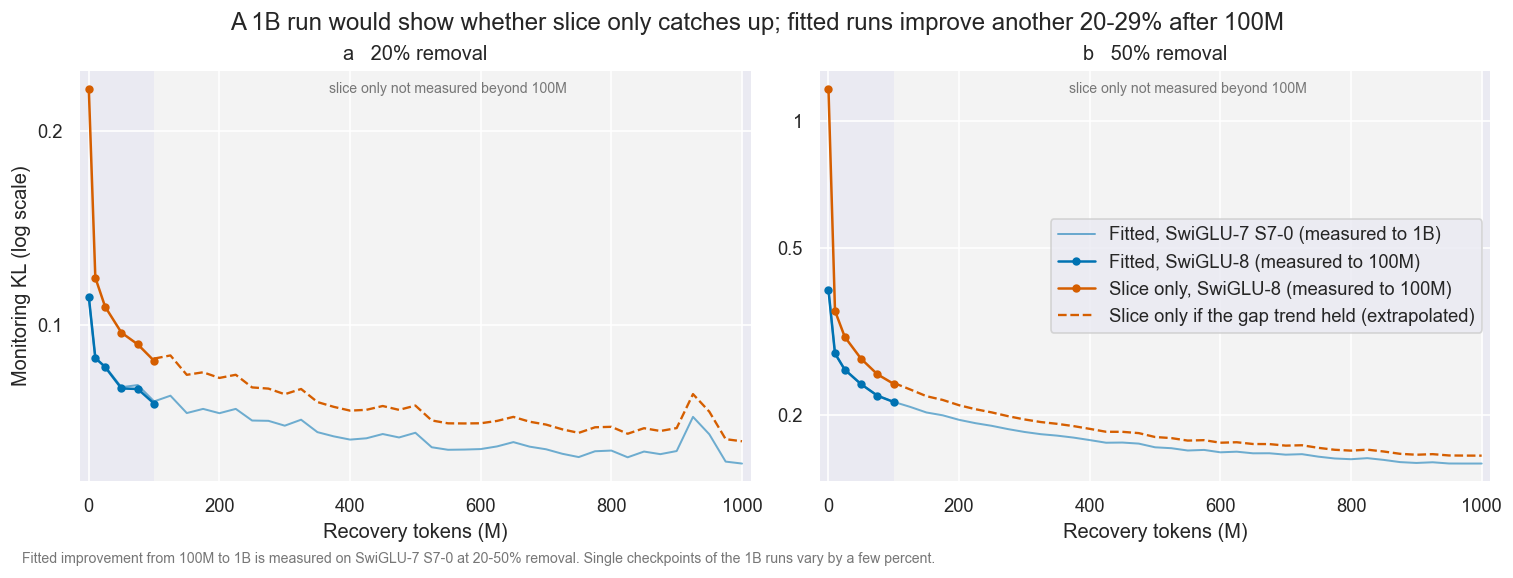

In [18]:
outlook_targets = [target for target in SHOWCASE_TARGETS if target in swiglu7_runs]
figure, axes = plt.subplots(1, len(outlook_targets), figsize=(12.5, 4.5))
for axis, letter, target in zip(axes, 'ab', outlook_targets):
    reference = pd.DataFrame([
        {'Tokens': requested_tokens(row), 'KL': row['recovery_validation_kl']}
        for row in swiglu7_runs[target]['results']['recovery']['validation_history']
    ])
    axis.axvspan(100, 1000, color='#f3f3f3', linewidth=0, zorder=0)
    axis.plot(reference['Tokens'] / 1e6, reference['KL'], color=ARM_COLORS['fitted'], linewidth=1.2, alpha=0.55,
              label='Fitted, SwiGLU-7 S7-0 (measured to 1B)')
    for arm in ARMS:
        rows = history_df[(history_df['Arm'] == arm) & (history_df['Target'] == target)]
        axis.plot(rows['Tokens'] / 1e6, rows['Monitoring KL'], color=ARM_COLORS[arm], marker='o', markersize=4,
                  label=f'{ARM_LABELS[arm]}, SwiGLU-8 (measured to 100M)')
    fit = extrapolation_df.loc[target]
    future = reference[reference['Tokens'] >= 100_000_000]
    implied = future['KL'] * (1 + np.exp(fit['Intercept'] + fit['Slope'] * np.log(future['Tokens'])))
    axis.plot(future['Tokens'] / 1e6, implied, color=ARM_COLORS['slice'], linestyle='--', linewidth=1.4,
              label='Slice only if the gap trend held (extrapolated)')
    axis.set(yscale='log', xlim=(-15, 1015), xlabel='Recovery tokens (M)', title=f'{letter}   {target:.0%} removal')
    axis.text(550, 0.97, 'slice only not measured beyond 100M', transform=axis.get_xaxis_transform(), ha='center',
              va='top', fontsize=8.5, color=NOTE_COLOR)
    axis.yaxis.set_major_locator(LogLocator(base=10, subs=(1.0, 2.0, 5.0)))
    axis.yaxis.set_major_formatter(FuncFormatter(lambda value, _: f'{value:g}'))
    axis.yaxis.set_minor_formatter(NullFormatter())
axes[0].set_ylabel('Monitoring KL (log scale)')
axes[-1].legend(loc='center right')
all_improvement = [1 - swiglu7_runs[target]['results']['recovery']['validation_history'][-1]['recovery_validation_kl']
                   / next(row['recovery_validation_kl'] for row in swiglu7_runs[target]['results']['recovery']['validation_history']
                          if requested_tokens(row) == 100_000_000) for target in swiglu7_runs]
figure.suptitle(
    f'A 1B run would show whether slice only catches up; fitted runs improve another '
    f'{100 * min(all_improvement):.0f}-{100 * max(all_improvement):.0f}% after 100M',
)
figure.text(0.01, -0.03, 'Fitted improvement from 100M to 1B is measured on SwiGLU-7 S7-0 at 20-50% removal. '
            'Single checkpoints of the 1B runs vary by a few percent.', fontsize=8.5, color=NOTE_COLOR)
plt.show()

#### Appendix: acceptance checks and data audit

In [19]:
acceptance_df['Relative difference'] = pd.to_numeric(acceptance_df['Relative difference'], errors='coerce')
acceptance_df['Tolerance'] = pd.to_numeric(acceptance_df['Tolerance'], errors='coerce')
show_table(
    acceptance_df.groupby(['Stage', 'Group'], sort=False).agg(
        Checks=('Passed', 'size'), **{'Within tolerance': ('Passed', 'sum'),
                                      'Largest relative difference': ('Relative difference', 'max'),
                                      'Tolerance': ('Tolerance', 'max')},
    ).reset_index(),
    'A1-A3 and P1-P3 reproduce SwiGLU-7; P4 checks the recovery stream; P5 scores the teacher against itself; '
    'B1 is exact at token 0, B2 is reviewed against 1%',
    {'Largest relative difference': '{:.2e}', 'Tolerance': '{:.0e}'},
)
flagged = acceptance_df[~acceptance_df['Passed']]
show_table(flagged[['Stage', 'Run', 'Group', 'Metric', 'Tokens', 'Value', 'Reference', 'Relative difference', 'Tolerance']],
           'Values outside tolerance: both are B2 single-checkpoint bumps, reviewed as noise in section 3d',
           {'Tokens': '{:,.0f}', 'Value': '{:.6f}', 'Reference': '{:.6f}', 'Relative difference': '{:.2%}', 'Tolerance': '{:.0%}'})

Stage,Group,Checks,Within tolerance,Largest relative difference,Tolerance
Part A block check,P5,1,1,-,1e-06
Part A block check,A1,6,6,0.00e+00,1e-04
Part A block check,A2-A3,18,18,0.00e+00,1e-03
Part B preparation,P4,1,1,-,-
Part B preparation,P3,12,12,0.00e+00,1e-04
Part B preparation,P5,2,2,-,1e-06
Part B preparation,P1,135,135,0.00e+00,1e-04
Part B preparation,P2,92,92,0.00e+00,1e-03
Part B recovery,B1,8,8,0.00e+00,1e-04
Part B recovery,B2,36,34,3.54e-02,1e-02


Stage,Run,Group,Metric,Tokens,Value,Reference,Relative difference,Tolerance
Part B recovery,fitted 20%,B2,recovery_validation_kl,"75,005,952",0.079554,0.080681,1.40%,1%
Part B recovery,fitted 30%,B2,recovery_validation_kl,"100,000,000",0.116592,0.112604,3.54%,1%


In [20]:
long_context = block_results['long_context_data']
audit = long_context['audit']
stream_roles = {
    'kl_stream': 'final 8K KL (Part B, Quantization-1)',
    'calibration_stream': '8K training pairs',
    'validation_stream': '8K early stopping',
    'selection_stream': 'Part A 8K score',
}
show_table(pd.DataFrame([
    {
        'Stream': name.removesuffix('_stream'), 'Role': role,
        'Tokens': long_context[name]['token_count'], 'Documents': long_context[name]['documents_consumed'],
        'First record': long_context[name].get('first_record', audit['kl_record_range'][0]),
        'Last record': long_context[name].get('last_record', audit['kl_record_range'][1]),
        'Skipped 128-token records': long_context[name].get('excluded_records_skipped', 0),
        'sha256': long_context[name]['sha256'][:16],
    }
    for name, role in stream_roles.items()
]), 'C4 shard-0 8K streams in document order', {'Tokens': '{:,}'})
print(f"No two 8K streams share a document: {audit['document_disjoint']}")
print('128-token windows drawn from 8K-KL documents (pre-existing SwiGLU-7 overlap):', audit['local_windows_from_kl_records'])
print(f"8K KL stream sha256 (compare with Quantization-1): {long_context['kl_stream']['sha256']}")
print(f"100M recovery stream: {prepared_results['stream']['token_count']:,} tokens, sha256 {prepared_results['stream']['sha256']}")

show_table(pd.DataFrame([
    {
        'Target': row['target'], 'Changed layers': len(row['changed_layers']),
        'Changes': ', '.join(f"L{change['layer']}: {change['swiglu7_width']} → {change['resolved_width']}"
                             for change in row['changed_layers']) or '-',
        'SwiGLU-7 predicted KL': row['swiglu7_predicted_teacher_kl'],
        'Re-solved predicted KL': row['resolved_predicted_teacher_kl'],
    }
    for row in prepared_results['allocation']['swiglu7_width_resolve_report']
]), 'Would the extended width menu change the 20-50% allocations? Reported only; the runs keep SwiGLU-7 widths',
   {'Target': '{:.0%}', 'SwiGLU-7 predicted KL': '{:.5f}', 'Re-solved predicted KL': '{:.5f}'})

Stream,Role,Tokens,Documents,First record,Last record,Skipped 128-token records,sha256
kl,"final 8K KL (Part B, Quantization-1)","196,608",409,0,408,0,ee134d3d230050bb
calibration,8K training pairs,"393,216",763,409,1174,3,00dc4a4652ec3bfb
validation,8K early stopping,"8,192",22,1175,1196,0,55342f1771758ea4
selection,Part A 8K score,"196,608",402,1197,1601,3,85165ff8d0eb9711


No two 8K streams share a document: True
128-token windows drawn from 8K-KL documents (pre-existing SwiGLU-7 overlap): {'calibration': 0, 'operator_validation': 0, 'old_recovery': 0, 'recovery_validation': 0, 'additional_calibration': 2, 'allocation_selection': 0, 'appended_calibration': 3}
8K KL stream sha256 (compare with Quantization-1): ee134d3d230050bbf84794e9fdc5f968cb06d0048490751a4de4a6e8e1bccdb5
100M recovery stream: 100,000,000 tokens, sha256 570409c133a6e14975485b516a12b774d0f2916345455b652d2bf09f95d3f2d7


Target,Changed layers,Changes,SwiGLU-7 predicted KL,Re-solved predicted KL
20%,0,-,0.09008,0.09008
30%,0,-,0.14812,0.14812
40%,0,-,0.21442,0.21442
50%,2,"L7: 3072 → 4096, L11: 2048 → 1024",0.29492,0.29464


#### Compute and deployment

Times come from each artifact's `created_at_utc` to `updated_at_utc` on one H200 per job. They are workflow proxies, not scheduler allocation; `sacct` is disabled on PERUN. Scheduler records, failures and retries are in `docs/infrastructure/perun/perun-log.md`.

In [21]:
block_tasks = block_results['tasks']
train_hours = [workflow_hours(run) for run in runs.values()]
first_attempt_hours = [workflow_hours(artifact) for artifact in first_attempts.values()]
stage_df = pd.DataFrame([
    {'Stage': 'A: block check', 'Jobs': len(block_tasks), 'Time limit (h)': REQUESTED_HOURS['block-check'],
     'Planned GPU-h': '{}-{}'.format(*PLANNED_GPU_HOURS['block-check']),
     'Measured GPU-h': sum(workflow_hours(task) for task in block_tasks),
     'Longest job (h)': max(workflow_hours(task) for task in block_tasks)},
    {'Stage': 'B0: prepare', 'Jobs': 1, 'Time limit (h)': REQUESTED_HOURS['prepare'],
     'Planned GPU-h': '{}-{}'.format(*PLANNED_GPU_HOURS['prepare']),
     'Measured GPU-h': workflow_hours(prepared), 'Longest job (h)': workflow_hours(prepared)},
    {'Stage': 'B1: recovery runs', 'Jobs': len(runs), 'Time limit (h)': REQUESTED_HOURS['train'],
     'Planned GPU-h': '{}-{}'.format(*PLANNED_GPU_HOURS['train']),
     'Measured GPU-h': sum(train_hours), 'Longest job (h)': max(train_hours)},
    {'Stage': 'Failed: first attempts stopped by B2', 'Jobs': len(first_attempts), 'Time limit (h)': REQUESTED_HOURS['train'],
     'Planned GPU-h': '-', 'Measured GPU-h': sum(first_attempt_hours), 'Longest job (h)': max(first_attempt_hours)},
])
planned_total = [sum(bounds) for bounds in zip(*PLANNED_GPU_HOURS.values())]
show_table(stage_df, f"Measured {stage_df['Measured GPU-h'].sum():.1f} GPU-h against a plan of "
           f'{planned_total[0]}-{planned_total[1]} GPU-h', {'Measured GPU-h': '{:.2f}', 'Longest job (h)': '{:.2f}'})

recovery_runs = [run['results']['recovery'] for run in runs.values()]
run_metrics = {
    'Training (h)': [recovery['training_seconds'] / 3600 for recovery in recovery_runs],
    'Final evaluation (h)': [run['results']['final_evaluation_wall_seconds'] / 3600 for run in runs.values()],
    'Workflow span (h)': train_hours,
    'Training throughput (tokens/s per H200)': [recovery['tokens_seen'] / recovery['training_seconds'] for recovery in recovery_runs],
    'Peak RAM (GiB)': [recovery['memory']['peak_ram_gib'] for recovery in recovery_runs],
    'Peak VRAM (GiB)': [recovery['memory']['peak_vram_gib'] for recovery in recovery_runs],
    'Bundle (GiB)': list(final_df['Bundle GiB']),
}
requests = {'Workflow span (h)': f"{REQUESTED_HOURS['train']} h limit", 'Peak RAM (GiB)': f'{REQUESTED_RAM_GB} GB requested',
            'Peak VRAM (GiB)': '141 GB H200'}
show_table(pd.DataFrame([
    {'Per recovery run': name, 'Min': min(values), 'Max': max(values), 'Request': requests.get(name, '-')}
    for name, values in run_metrics.items()
]), f"16 recovery runs; {sum(run_metrics['Bundle (GiB)']):.1f} GiB of BF16 bundles on PROJECT; peak SCRATCH not recorded",
   {'Min': '{:,.2f}', 'Max': '{:,.2f}'})

show_table(pd.DataFrame([
    {
        'Artifact': name, 'Python': artifact['environment']['python'],
        'PyTorch': artifact['environment']['packages']['torch'],
        'Transformers': artifact['environment']['packages']['transformers'],
        'lm-eval': artifact['environment']['packages']['lm_eval'],
        'CUDA runtime': artifact['environment']['cuda_runtime'], 'GPU': artifact['environment']['gpu'],
    }
    for name, artifact in (('block check', block_check), ('prepare', prepared),
                           *((f'{arm} {target:.0%}', run) for (arm, target), run in runs.items()))
]).drop_duplicates(subset=['Python', 'PyTorch', 'Transformers', 'lm-eval', 'CUDA runtime', 'GPU']),
   'Distinct software and hardware environments')

Stage,Jobs,Time limit (h),Planned GPU-h,Measured GPU-h,Longest job (h)
A: block check,15,6,16-31,7.91,1.04
B0: prepare,1,24,3-8,3.36,3.36
B1: recovery runs,16,6,20-24,20.18,1.33
Failed: first attempts stopped by B2,4,6,-,0.68,0.28


Per recovery run,Min,Max,Request
Training (h),0.91,1.05,-
Final evaluation (h),0.23,0.24,-
Workflow span (h),1.18,1.33,6 h limit
Training throughput (tokens/s per H200),"26,556.64","30,537.08",-
Peak RAM (GiB),5.18,8.80,128 GB requested
Peak VRAM (GiB),25.08,33.48,141 GB H200
Bundle (GiB),1.54,2.78,-


Artifact,Python,PyTorch,Transformers,lm-eval,CUDA runtime,GPU
block check,3.12.14,2.11.0+cu128,5.14.1,0.4.13,12.8,NVIDIA H200


**Recommendation for the next request.** A 100M recovery run used at most about 1.3 h of its 6 h limit and under 9 GiB of the 128 GB of RAM requested. A 1B follow-up run should request about 14 h, roughly ten times the measured training time plus the final evaluation and a margin. 32 GB of RAM would still leave more than 3× headroom.